Relative synapse count of serotonergic cell types across neuropils (normalization by the sum of synapses on the whole brain level)

Number of rows (before filtering): 211695

Cell types in dataset:
['l-LNv' 'R8' 'R1-6' 'L3' 'cM08a' 'DNp27' 'SLP444' 'cL19' 'AN_multi_124'
 'CSD' '5th-LNv' 'DNp30' 'NPFL1-I' 'CB2188' 'AVLP218b' 'DNg30' 'SMP001'
 'AVLP594' 'AVLP219a' 'AN_SLP_AVLP_1' 'DNp29' 'SLP304b' 'CRZ01' 'T1'
 'CB1101' 'AVLP441' 'CL107' 'SMPp&v1B_H01' 'DNp62' 'SLP403' 'R7' 'CL255'
 '5-HTPMPV01' 'lLN2X03' 'SMP582' 'lLN2T_c' 'ORN_DM2' 'FB1A' 'CB0262'
 'lLN2T_b' 'ORN_VA1v' 'vDeltaI_a' 'ORN_DA4l' 'FB4Y' 'AN_GNG_77' 'ORN_DC1'
 'AN_GNG_SAD_28' 'lLN1_a' 'ORN_DL4' 'BM_InOm' 'LAL082' 'CB0212' 'lLN2T_e'
 'SMPp&v1B_M02' 'ORN_VA2' 'AVLP461' 'lLN2X05' 'IB048' 'GNG800f' 'vDeltaC'
 'ORN_DM3' 'lLN2X11' 'ATL034' 'AN_GNG_SAD_22' 'ORN_VL1' 'CB0878' 'ORN_DL3'
 'CB0602' nan 'AN_FLA_SMP_2' 'SMP590' 'CB0722' 'CB4148' 'AN_GNG_69' 'FB4J'
 'CB1537' 'ocellar_retinula_cell' 'DNge094' 'AN_FLA_SMP_1' 'ORN_V'
 'DNpe048' 'DNpe007' 'v2LN36' 'AN_GNG_SAD_20' 'CB1037' 'CB3366' 'AVLP155'
 'CB1190' 'FB4K' 'ENS3' 'SA_MDA_3' 'PFGs' 'DNg65' 'AN_GNG_SAD_27'

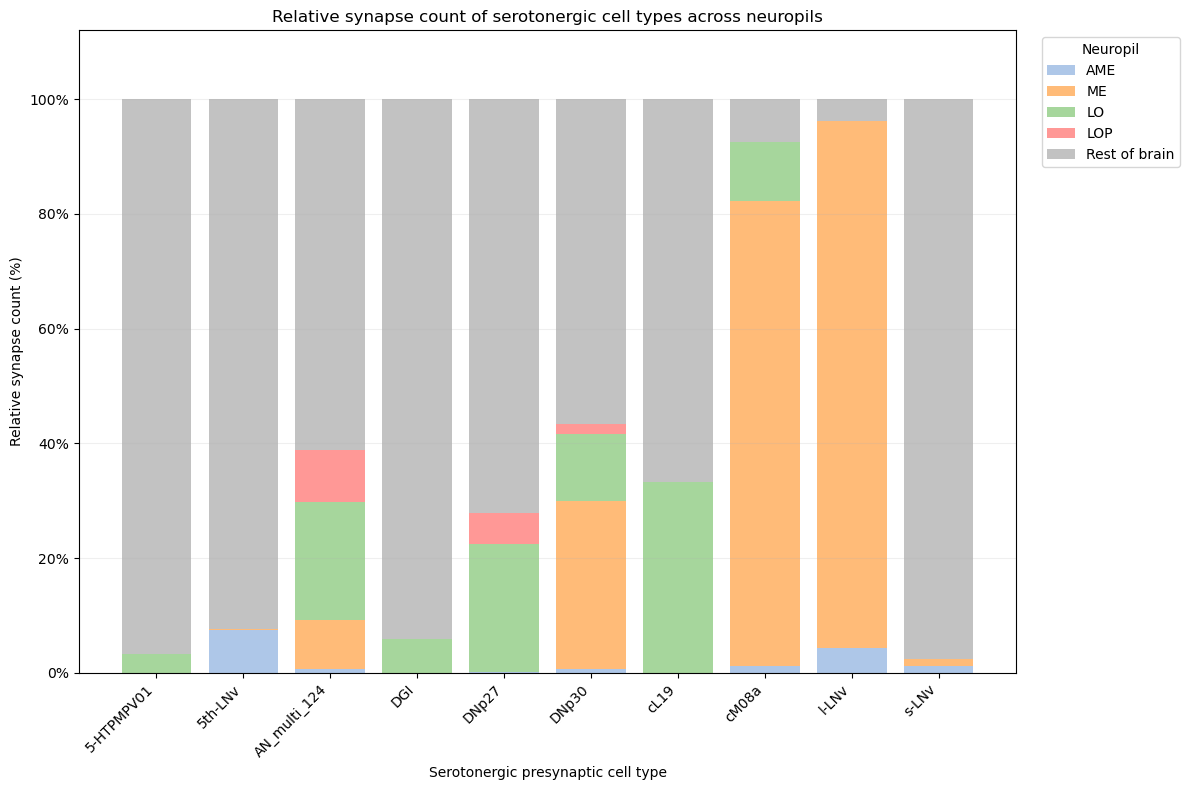


Done!

PNG:
C:\Users\krist\OneDrive\Desktop\B' module\serotonergic_distribution_across_neuropils\serotonergic_region_distribution_filtered.png

SVG:
C:\Users\krist\OneDrive\Desktop\B' module\serotonergic_distribution_across_neuropils\serotonergic_region_distribution_filtered.svg

Percentage table:
C:\Users\krist\OneDrive\Desktop\B' module\serotonergic_distribution_across_neuropils\serotonergic_region_percentages_filtered.csv


In [ ]:
# Main goal of the following code: For 10 selected serotonergic cell types (identified from Codex), we determine where in the brain 
# their synapses are located, specifically how much lies in the D. melanogaster optic lobe (OL) regions (AME, ME, LO, LOP), 
# as compared to the rest of the brain.

# What does the plot show? A 100% stacked bar chart with one bar per serotonergic cell type. Each bar shows the percentage of that 
# cell type's synapses in AME, ME, LO, LOP and "Rest of brain" (Left-Right hemispheres are merged for each neuropil region). 
# The y-axis is percentage of synapses, and the x-axis is the serotonergic cell type. 
# The plot shows the relative distribution of synapses across the five regions for each cell type, rather than absolute synapse counts.

#######################################################################################################################################

# We import the necessary libraries for file handling, data manipulation, and plotting. 

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# We define the input and output paths. The input is a filtered CSV file containing synapse data for serotonergic cell types,
# and the output is a folder where we will save the resulting plots. 

relative_synapse_count_folder = Path(r"C:\Users\krist\OneDrive\Desktop\B' module")

# The filtered CSV (input file)
input_file = relative_synapse_count_folder / "connections_princeton_SER_only_annotated_whole_brain.csv"

# The output folder fo the plots 
output_dir = relative_synapse_count_folder / "serotonergic_distribution_across_neuropils"
output_dir.mkdir(parents=True, exist_ok=True)

# We define the column names in the input CSV that we will use for the analysis. 

cell_type_col = "annotation_primary_type"
neuropil_col = "neuropil"
syn_count_col = "syn_count"

# We read the input CSV file into a pandas DataFrame and print the number of rows before filtering, as well as the 
# unique cell types present in the dataset. 

# We want to document the number of rows before filtering, as well as the unique cell types present in the dataset.

data_frame_relative_synapse_count = pd.read_csv(input_file)

print("Number of rows (before filtering):", len(data_frame_relative_synapse_count))

print("\nCell types in dataset:")
print(data_frame_relative_synapse_count[cell_type_col].unique())

# We filter the DataFrame to only include the 9 selected serotonergic cell types, and print the number of rows after filtering. 

selected_serotonergic_cell_types = [
    "5-HTPMPV01",
    "5th-LNv",
    "AN_multi_124",
    "DGI",
    "DNp27",
    "DNp30",
    "cL19",
    "cM08a",
    "l-LNv",
    "s-LNv"
]

data_frame_relative_synapse_count = data_frame_relative_synapse_count[data_frame_relative_synapse_count[cell_type_col].isin(selected_serotonergic_cell_types)].copy()

# We check if any of the selected cell types are missing from the filtered DataFrame, and print a warning if so. 

print("\nNumber of rows (after filtering):", len(data_frame_relative_synapse_count))

found_types = set(data_frame_relative_synapse_count[cell_type_col].unique())
missing_types = [ct for ct in selected_serotonergic_cell_types if ct not in found_types]

if missing_types:
    print("\nWARNING: these requested cell types had 0 matching rows:")
    print(missing_types)
    print("Double-check spelling/formatting against the actual unique values above.")

# We clean the DataFrame by dropping rows with missing values in the relevant columns, and converting the synapse count column to numeric 
# because it may have been read as a string. We then drop any rows where the synapse count is still missing after conversion. 

data_frame_relative_synapse_count = data_frame_relative_synapse_count.dropna(
    subset=[
        cell_type_col,
        neuropil_col,
        syn_count_col
    ]
).copy()

data_frame_relative_synapse_count[syn_count_col] = pd.to_numeric(
    data_frame_relative_synapse_count[syn_count_col],
    errors="coerce"
)

data_frame_relative_synapse_count = data_frame_relative_synapse_count.dropna(
    subset=[syn_count_col]
)

# We define the target neuropil regions of interest for the analysis, which are AME, ME, LO, and LOP.
# All other neuropil regions will be classified as "Rest of brain" in the analysis. 

#    AME for the Accessory Medulla
#    ME for the Medulla
#    LO for the Lobula
#    LOP for the Lobula Plate
#
#    Everything else = Rest of brain
# ============================================================

target_neuropil_regions = {
    "AME", # accessory medulla
    "ME",  # medulla
    "LO",  # lobula
    "LOP"  # lobula plate
}

# We define a function to classify each neuropil region in the DataFrame. 
# If the neuropil region ends with "L" or "R", we remove that suffix to merge left and right hemispheres. 

def classify_neuropil(neuropil):

    neuropil = str(neuropil).strip()

    if neuropil.endswith("_L") or neuropil.endswith("_R"):
        neuropil = neuropil[:-2]

    if neuropil in target_neuropil_regions:
        return neuropil

    return "Rest of brain"


data_frame_relative_synapse_count["region"] = data_frame_relative_synapse_count[neuropil_col].apply(
    classify_neuropil
)

# We summarize the synapse counts by cell type and region, summing the synapse counts for each combination of cell type and region.

summary_synapse_counts = (
    data_frame_relative_synapse_count
    .groupby(
        [
            cell_type_col,
            "region"
        ],
        as_index=False
    )[syn_count_col]
    .sum()
)

# We calculate the total synapse count for each cell type by summing the synapse counts across all regions for that cell type. 
# Difference from above: we use transform ("sum") to create a Series that aligns with the original DataFrame, so we can
# calculate percentages in the next step. 

total_per_cell_type = (
    summary_synapse_counts
    .groupby(cell_type_col)[syn_count_col]
    .transform("sum")
)

# We calculate the percentage of synapses in each region for each cell type by dividing the synapse count for that region by the 
# total synapse count for that cell type, and multiplying by 100 to get a percentage. 

summary_synapse_counts["percentage"] = (
    summary_synapse_counts[syn_count_col]
    / total_per_cell_type
    * 100
)
# We define the list of neuropil regions in the order we want them to appear in the plot, which is AME, ME, LO, LOP, and "Rest of brain".

neuropil_regions = [
    "AME",
    "ME",
    "LO",
    "LOP",
    "Rest of brain"
]

# We create a full index of all combinations of cell types and neuropil regions, so that we can ensure that every cell type has an entry
# for every neuropil region, even if the synapse count is zero. This is important for plotting, so that all bars have the same number of
# segments.

cell_types = sorted(
    summary_synapse_counts[cell_type_col].unique()
)

full_index = pd.MultiIndex.from_product(
    [
        cell_types,
        neuropil_regions
    ],
    names=[
        cell_type_col,
        "region"
    ]
)

# We reindex the summary_synapse_counts DataFrame to include all combinations of cell types and neuropil regions, filling in any missing
# combinations with a synapse count of zero. This ensures that every cell type has an entry for every neuropil region, even if the synapse 
# count is zero. We reset the index to turn the MultiIndex back into columns. 

summary_synapse_counts = (
    summary_synapse_counts
    .set_index(
        [
            cell_type_col,
            "region"
        ]
    )
    .reindex(
        full_index,
        fill_value=0
    )
    .reset_index()
)

# We pivot the summary_synapse_counts DataFrame to create a new DataFrame where the index is the cell type, the columns are the neuropil regions, 
# and the values are the percentages of synapses in each region. We fill any missing values with zero, so that every cell type has an entry for
# every neuropil region, even if the synapse count is zero. We also ensure that the columns are in the order we want for plotting. 

plot_data = (
    summary_synapse_counts
    .pivot(
        index=cell_type_col,
        columns="region",
        values="percentage"
    )
    .fillna(0)
)


plot_data = plot_data[
    neuropil_regions
]

# We print the percentage totals for each cell type, which should sum to 100% across all neuropil regions. 
# This is a sanity check to ensure that the percentages were calculated correctly. 

print("\nPercentage totals:")

for cell_type, total in plot_data.sum(axis=1).items():

    print(
        f"{cell_type}: {total:.2f}%"
    )

# We save the percentage data to a CSV file in the output directory, so that we have a record of the calculated percentages
# for each cell type and neuropil region. This allows for further analysis or verification of the results. 

values_file = (
    output_dir /
    "serotonergic_region_percentages_filtered.csv"
)

plot_data.to_csv(
    values_file
)

# We create a stacked bar chart to visualize the relative synapse counts of serotonergic cell types across neuropil regions. 

fig, ax = plt.subplots(
    figsize=(
        max(12, len(plot_data) * 1.0),
        8
    )
)

# We define a color palette for the neuropil regions using the Set3 colormap from Matplotlib. Each region is assigned a specific
# color for visual distinction in the stacked bar chart. The colors are chosen to be visually distinct and easily identifiable. 
set3 = plt.get_cmap("Set3").colors

region_colors = {
    "AME": "#AEC7E8",
    "ME": "#FFBB78",
    "LO": "#A6D69C",
    "LOP": "#FF9896",
    "Rest of brain": "#C2C2C2"
}

bottom = None

# We iterate over the neuropil regions and plot the percentage of synapses for each region as a stacked bar for each serotonergic 
# cell type. The 'bottom' parameter is used to stack the bars on top of each other, creating a cumulative effect. 

for region in neuropil_regions:

    values = plot_data[region].values

    ax.bar(
        plot_data.index,
        values,
        bottom=bottom,
        label=region,
        color=region_colors[region]
    )

    if bottom is None:
        bottom = values.copy()

    else:
        bottom += values

# We set the x-axis label, y-axis label, and title for the plot to provide context and information about what the plot represents. 

ax.set_xlabel(
    "Serotonergic presynaptic cell type"
)

ax.set_ylabel(
    "Relative synapse count (%)"
)

ax.set_title(
    "Relative synapse count of serotonergic cell types across neuropils"
)

# We add extra headroom above 100% on the y-axis to ensure that the top of the bars does not touch the top of the plot area,
# making it visually clearer. The y-axis is formatted to show percentages, and tick marks are set to only go up to 100% to 
# emphasize that the headroom is empty space rather than a labeled range. 

y_headroom = 12  # extra space above 100% for visual clarity

ax.set_ylim(
    0,
    100 + y_headroom
)

ax.yaxis.set_major_formatter(
    PercentFormatter(100)
)

# We set the y-axis ticks to be at intervals of 20%, which provides a clear and easy-to-read scale for interpreting the relative
# synapse counts in the stacked bar chart. This choice of tick intervals helps to avoid clutter and makes it easier to compare the 
# heights of the stacked bars across different serotonergic cell types. 

ax.set_yticks(range(0, 101, 20))

# We set the x-axis ticks to correspond to the number of serotonergic cell types, ensuring that each bar is labeled correctly. 

ax.set_xticks(
    range(len(plot_data.index))
)

ax.set_xticklabels(
    plot_data.index,
    rotation=45,
    ha="right"
)

# We add a legend to the plot to indicate which colors correspond to which neuropil regions. The legend is placed outside the main plot area. 

ax.legend(
    title="Neuropil",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)


ax.grid(
    axis="y",
    alpha=0.2
)

# We adjust the layout of the plot to ensure that all elements are displayed properly and that there is no overlap between labels, titles, and
# the plot area. This is especially important when saving the plot to a file to ensure that all elements are visible and the plot is aesthetically pleasing. 

fig.tight_layout()


png_file = (
    output_dir /
    "serotonergic_region_distribution_filtered.png"
)

svg_file = (
    output_dir /
    "serotonergic_region_distribution_filtered.svg"
)

fig.savefig(
    png_file,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    svg_file,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)

# We print the paths to the saved plot files and the percentage table CSV file, so that the user knows where to find the output files. 

print("\nDone!")

print("\nPNG:")
print(png_file)

print("\nSVG:")
print(svg_file)

print("\nPercentage table:")
print(values_file)


Absolute synapse count of serotonergic cell types across neuropils

Number of rows (before filtering): 211695

Cell types in dataset:
['l-LNv' 'R8' 'R1-6' 'L3' 'cM08a' 'DNp27' 'SLP444' 'cL19' 'AN_multi_124'
 'CSD' '5th-LNv' 'DNp30' 'NPFL1-I' 'CB2188' 'AVLP218b' 'DNg30' 'SMP001'
 'AVLP594' 'AVLP219a' 'AN_SLP_AVLP_1' 'DNp29' 'SLP304b' 'CRZ01' 'T1'
 'CB1101' 'AVLP441' 'CL107' 'SMPp&v1B_H01' 'DNp62' 'SLP403' 'R7' 'CL255'
 '5-HTPMPV01' 'lLN2X03' 'SMP582' 'lLN2T_c' 'ORN_DM2' 'FB1A' 'CB0262'
 'lLN2T_b' 'ORN_VA1v' 'vDeltaI_a' 'ORN_DA4l' 'FB4Y' 'AN_GNG_77' 'ORN_DC1'
 'AN_GNG_SAD_28' 'lLN1_a' 'ORN_DL4' 'BM_InOm' 'LAL082' 'CB0212' 'lLN2T_e'
 'SMPp&v1B_M02' 'ORN_VA2' 'AVLP461' 'lLN2X05' 'IB048' 'GNG800f' 'vDeltaC'
 'ORN_DM3' 'lLN2X11' 'ATL034' 'AN_GNG_SAD_22' 'ORN_VL1' 'CB0878' 'ORN_DL3'
 'CB0602' nan 'AN_FLA_SMP_2' 'SMP590' 'CB0722' 'CB4148' 'AN_GNG_69' 'FB4J'
 'CB1537' 'ocellar_retinula_cell' 'DNge094' 'AN_FLA_SMP_1' 'ORN_V'
 'DNpe048' 'DNpe007' 'v2LN36' 'AN_GNG_SAD_20' 'CB1037' 'CB3366' 'AVLP155'
 'CB1190' 'FB4K' 'ENS3' 'SA_MDA_3' 'PFGs' 'DNg65' 'AN_GNG_SAD_27'

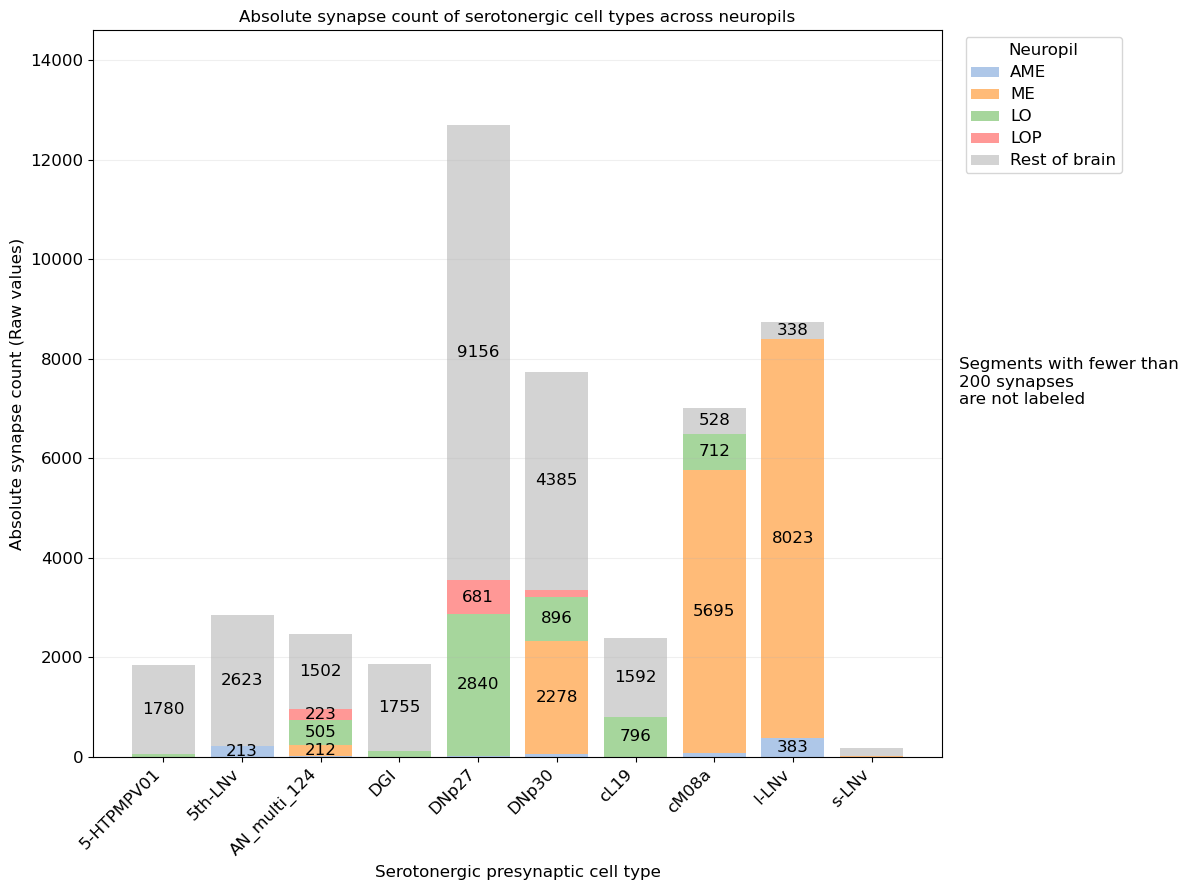


Done!

PNG:
C:\Users\krist\OneDrive\Desktop\B' module\total_serotonergic_distribution_across_neuropils\serotonergic_region_distribution_counts.png

SVG:
C:\Users\krist\OneDrive\Desktop\B' module\total_serotonergic_distribution_across_neuropils\serotonergic_region_distribution_counts.svg

Count table:
C:\Users\krist\OneDrive\Desktop\B' module\total_serotonergic_distribution_across_neuropils\serotonergic_absolute_region_counts_filtered.csv


In [25]:
# Main goal of the following code: For the 9 selected serotonergic cell types, we determine where in the brain their synapses are located, 
# specifically how many lie in the optic lobe regions (AME, ME, LO, LOP) versus the rest of the brain.

# What does the plot show? A stacked bar chart with one bar per cell type, showing the absolute (raw) synapse counts in AME, ME, LO, LOP and "Rest of brain" 
# (left/right hemispheres merged). Bar height therefore reflects each cell type's total synapse number, and segment labels give the raw count 
# (segments under 200 synapses are left unlabeled).

############################################################################################################################################################

# We import the necessary libraries for file handling, data manipulation, and plotting. 

from pathlib import Path
from igraph import summary
import pandas as pd
import matplotlib.pyplot as plt

# We define the input and output paths. The input is a filtered CSV file containing synapse data for serotonergic cell types. 

absolute_synapse_count_folder = Path(r"C:\Users\krist\OneDrive\Desktop\B' module")

input_file = absolute_synapse_count_folder / "connections_princeton_SER_only_annotated_whole_brain.csv"

output_dir = absolute_synapse_count_folder / "total_serotonergic_distribution_across_neuropils"
output_dir.mkdir(parents=True, exist_ok=True)


# We define the column names in the input CSV that we will use for the analysis. 

cell_type_col = "annotation_primary_type"
neuropil_col = "neuropil"
syn_count_col = "syn_count"


# We read the input CSV file into a pandas DataFrame and print the number of rows before filtering, as well as the unique cell types present in the dataset.

data_frame_absolute_synapse_count = pd.read_csv(input_file)

print("Number of rows (before filtering):", len(data_frame_absolute_synapse_count))
print("\nCell types in dataset:")
print(data_frame_absolute_synapse_count[cell_type_col].unique())


# We filter the DataFrame to only include the 9 selected serotonergic cell types, and print the number of rows before filtering. 

selected_cell_types = [
    "5-HTPMPV01",
    "5th-LNv",
    "AN_multi_124",
    "DGI",
    "DNp27",
    "DNp30",
    "cL19",
    "cM08a",
    "l-LNv",
    "s-LNv"
]

data_frame_absolute_synapse_count = data_frame_absolute_synapse_count[data_frame_absolute_synapse_count[cell_type_col].isin(selected_cell_types)].copy()

print("\nNumber of rows (after filtering):", len(data_frame_absolute_synapse_count))

found_types = set(data_frame_absolute_synapse_count[cell_type_col].unique())
missing_types = [ct for ct in selected_cell_types if ct not in found_types]

if missing_types:
    print("\nWARNING: these requested cell types had 0 matching rows:")
    print(missing_types)


# We clean the DataFrame by dropping rows with missing values in the relevant columns, and converting the synapse count column to numeric. 
# Why do we do that? Because the synapse count column may have been read as a string, and we need it to be numeric for calculations. 


data_frame_absolute_synapse_count = data_frame_absolute_synapse_count.dropna(subset=[cell_type_col, neuropil_col, syn_count_col]).copy()
data_frame_absolute_synapse_count[syn_count_col] = pd.to_numeric(data_frame_absolute_synapse_count[syn_count_col], errors="coerce")
data_frame_absolute_synapse_count = data_frame_absolute_synapse_count.dropna(subset=[syn_count_col])


# We define the target neuropil regions of interest for the analysis, which are AME, ME, LO, and LOP. All other neuropil regions will be classified as 
# "Rest of brain" in the analysis. 

target_neuropil_regions = {"AME", "ME", "LO", "LOP"}

# We define a function to classify each neuropil region in the DataFrame. If the neuropil region ends with "L" or "R", we remove that suffix to merge left and right hemispheres. 

def classify_neuropil(neuropil):
    neuropil = str(neuropil).strip()
    if neuropil.endswith("_L") or neuropil.endswith("_R"):
        neuropil = neuropil[:-2]
    if neuropil in target_neuropil_regions:
        return neuropil
    return "Rest of brain"

# We apply the classify_neuropil function to the neuropil column of the DataFrame to create a new column called "region". 
# This new column will contain the classified neuropil regions for each synapse, allowing us to group and summarize the data by these regions
# in subsequent analysis steps.  

data_frame_absolute_synapse_count["region"] = data_frame_absolute_synapse_count[neuropil_col].apply(classify_neuropil)

# We summarize the synapse counts by cell type and region, summing the synapse counts for each combination of cell type and region. 

summary_absolute_synapse_count= (
    data_frame_absolute_synapse_count.groupby([cell_type_col, "region"], as_index=False)[syn_count_col].sum()
)

# We create a full index of all combinations of cell types and neuropil regions, so that we can ensure that every cell type has an entry. 
# Why do we do that? Because some cell types may not have synapses in certain regions, and we want to include those combinations with a count of zero for completeness. 

regions = ["AME", "ME", "LO", "LOP", "Rest of brain"]
cell_types = sorted(summary_absolute_synapse_count[cell_type_col].unique())

full_index = pd.MultiIndex.from_product(
    [cell_types, regions], names=[cell_type_col, "region"]
)

summary_absolute_synapse_count = (
    summary_absolute_synapse_count.set_index([cell_type_col, "region"])
    .reindex(full_index, fill_value=0)
    .reset_index()
)


# We pivot the summary_absolute_synapse_count DataFrame to create a new DataFrame where the index is the cell type, the columns are the neuropil regions, 
# and the values are the absolute synapse counts in each region. We will fill any missing values with zero, so that every cell type has an entry for every
# neuropil region. This is important for plotting, so that all bars have the same number of segments. 

plot_data = summary_absolute_synapse_count.pivot(
    index=cell_type_col, columns="region", values=syn_count_col
).fillna(0)

plot_data = plot_data[regions]


# We print the total/absolute synapse counts per cell type, which is the sum of synapse counts across all neuropil regions for each cell type. 
# This provides a summary of the total synapse counts for each serotonergic cell type, allowing us to see which cell types have the most or least synapses overall. 

print("\nTotal synapse counts per cell type:")
for cell_type, total in plot_data.sum(axis=1).items():
    print(f"{cell_type}: {total:.0f}")


# We save the absolute synapse count data to a CSV file in the output directory, so that we have a record of the calculated counts. 

values_file = output_dir / "serotonergic_absolute_region_counts_filtered.csv"
plot_data.to_csv(values_file)


# We create a stacked bar chart to visualize the absolute synapse counts of serotonergic cell types across neuropils. 

fig, ax = plt.subplots(
    figsize=(
        max(12, len(plot_data) * 1.0),
        9
    )
)

# We define a color palette for the neuropil regions using the Set3 colormap from Matplotlib. Each region is assigned a specific
# color for visual distinction in the stacked bar chart. The colors are chosen to be virtually distinct and easily identifiable. 

region_colors = {
    "AME": "#AEC7E8",
    "ME": "#FFBB78",
    "LO": "#A6D69C",
    "LOP": "#FF9896",
    "Rest of brain": "lightgrey"
}

# A segment is only labeled with its raw count if it has at
# least this many synapses. This keeps tiny slivers from being
# cluttered with unreadable numbers.
min_label_count = 200

bottom = None

for region in regions:
    values = plot_data[region].values

    ax.bar(
        plot_data.index,
        values,
        bottom=bottom,
        label=region,
        color=region_colors[region]
    )

    if bottom is None:
        bottom = values.copy()
    else:
        bottom += values

    # Add a raw-count label centered in each bar segment,
    # skipping segments with too few synapses to label clearly.
    segment_bottom = bottom - values

    for x_pos, value, seg_bottom in zip(
        range(len(values)),
        values,
        segment_bottom
    ):

        if value >= min_label_count:

            ax.text(
                x_pos,
                seg_bottom + value / 2,
                f"{value:.0f}",
                ha="center",
                va="center",
                fontsize=12,
                fontweight="normal"
            )


# ============================================================
# 12. AXIS LABELS
# ============================================================

ax.set_xlabel(
    "Serotonergic presynaptic cell type",
    fontsize=12,
    fontweight="normal"
)

ax.set_ylabel(
    "Absolute synapse count (Raw values)",
    fontsize=12,
    fontweight="normal"
)

ax.set_title(
    "Absolute synapse count of serotonergic cell types across neuropils",
    fontsize=12,
    fontweight="normal"
)


# ============================================================
# 13. Y AXIS — auto-scaled, with headroom added above the tallest bar
# ============================================================

max_total = plot_data.sum(axis=1).max()
ax.set_ylim(0, max_total * 1.15)


# ============================================================
# 14. X AXIS
# ============================================================

ax.set_xticks(range(len(plot_data.index)))

ax.set_xticklabels(
    plot_data.index,
    rotation=45,
    ha="right",
    fontsize=12,
    fontweight="normal"
)

ax.tick_params(
    axis="y",
    labelsize=12
)

for label in ax.get_yticklabels():
    label.set_fontweight("normal")


# ============================================================
# 15. LEGEND
# ============================================================

legend = ax.legend(
    title="Neuropil",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

for text in legend.get_texts():
    text.set_fontsize(12)
    text.set_fontweight("normal")

legend.get_title().set_fontsize(12)
legend.get_title().set_fontweight("normal")


# Small note next to the legend explaining why some segments
# don't have a count label.
ax.text(
    1.02,
    0.55,
    f"Segments with fewer than\n{min_label_count:.0f} synapses\nare not labeled",
    transform=ax.transAxes,
    fontsize=12,
    fontweight="normal",
    va="top",
    ha="left"
)

ax.grid(axis="y", alpha=0.2)


# ============================================================
# 16. SAVE FIGURE
# ============================================================

fig.tight_layout()

png_file = output_dir / "serotonergic_region_distribution_counts.png"
svg_file = output_dir / "serotonergic_region_distribution_counts.svg"

fig.savefig(png_file, dpi=300, bbox_inches="tight")
fig.savefig(svg_file, bbox_inches="tight")

plt.show()
plt.close(fig)


# ============================================================
# 17. DONE
# ============================================================

print("\nDone!")
print("\nPNG:")
print(png_file)
print("\nSVG:")
print(svg_file)
print("\nCount table:")
print(values_file)



Distribution of serotonergic connections across hemispheres (left and right)


Hemisphere distribution:
hemisphere
Left       15537
Right      15162
Unknown     1080
Name: count, dtype: int64


L + R PERCENTAGE TOTALS
annotation_primary_type
5-HTPMPV01      100.0
5th-LNv         100.0
AN_multi_124    100.0
DGI             100.0
DNp27           100.0
DNp30           100.0
cL19            100.0
cM08a           100.0
l-LNv           100.0
s-LNv           100.0
dtype: float64

LEFT: PERCENTAGE DISTRIBUTION
region                    AME     ME     LO   LOP  Rest of brain
annotation_primary_type                                         
5-HTPMPV01               0.00   0.00   0.00  0.00          24.09
5th-LNv                  7.49   0.21   0.00  0.00          84.55
AN_multi_124             0.09   6.23  14.01  5.27          23.95
DGI                      0.00   0.00   0.00  0.00          20.37
DNp27                    0.12   0.00  12.25  1.51          40.85
DNp30                    0.26  15.52   7.34  0.83          29.60
cL19                     0.00   0.00  16.44  0.00 

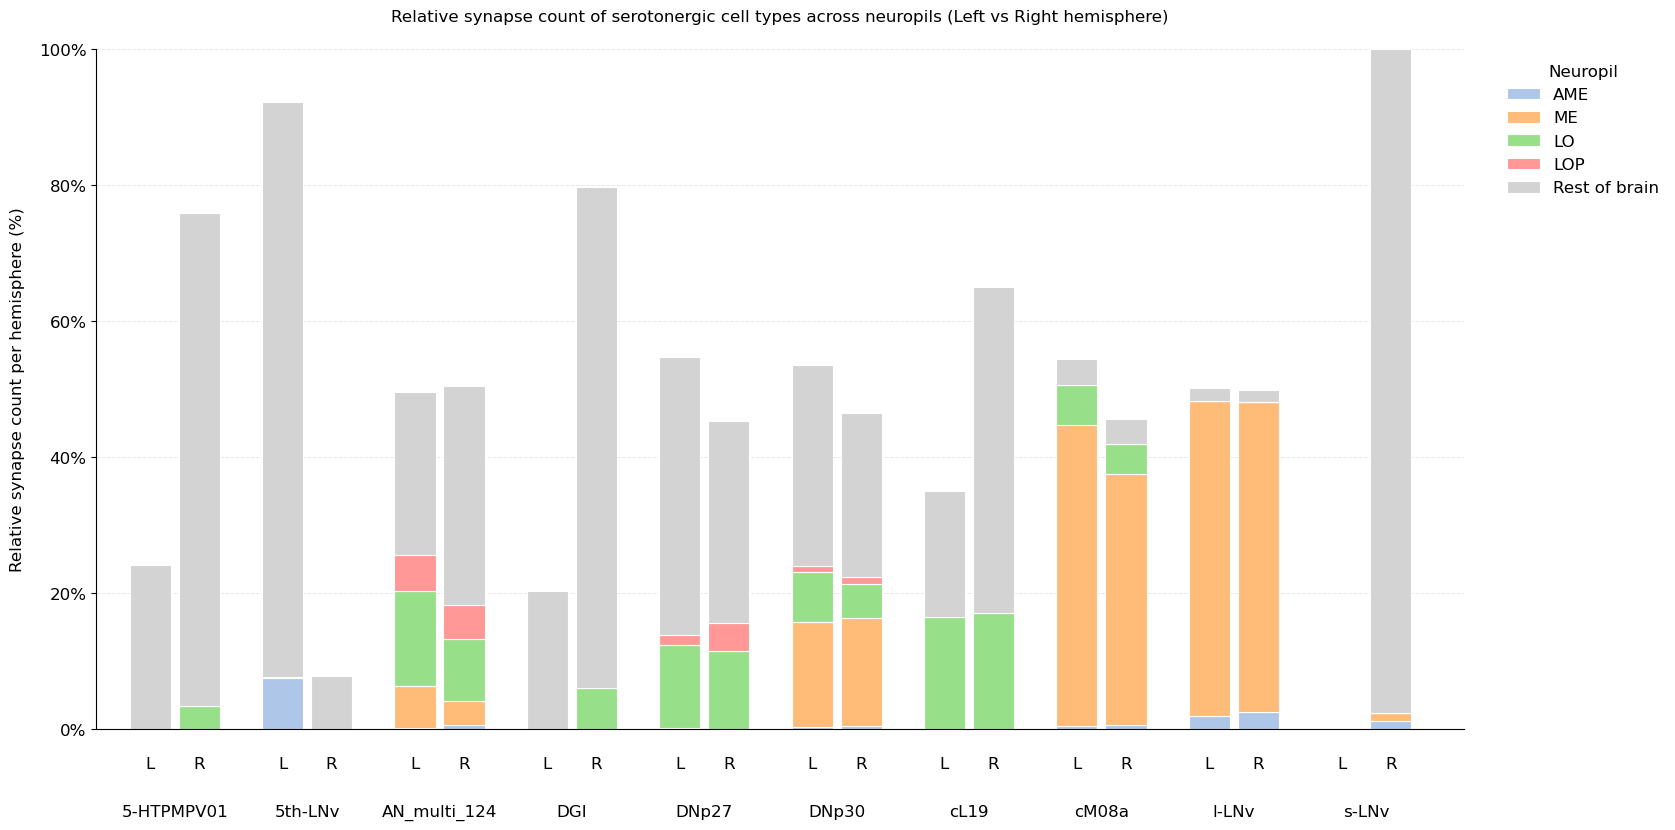

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. FILE PATH
# ============================================================

file_path = (
    r"C:\Users\krist\OneDrive\Desktop\B' module"
    r"\connections_princeton_SER_only_annotated_whole_brain.csv"
)


# ============================================================
# 2. LOAD DATA
# ============================================================

df = pd.read_csv(
    file_path
)


# ============================================================
# 3. COLUMN NAMES
# ============================================================

cell_type_col = "annotation_primary_type"
neuropil_col = "neuropil"
synapse_col = "syn_count"


# ============================================================
# 4. SELECT SEROTONERGIC CELL TYPES
#
#    "s-LNv" removed from the analysis.
# ============================================================

selected_cell_types = [
    "5-HTPMPV01",
    "5th-LNv",
    "AN_multi_124",
    "DGI",
    "DNp27",
    "DNp30",
    "cL19",
    "cM08a",
    "l-LNv",
    's-LNv'
]


# ============================================================
# 5. TARGET BRAIN REGIONS
# ============================================================

regions = [
    "AME",
    "ME",
    "LO",
    "LOP",
    "Rest of brain"
]

hemispheres = [
    "Left",
    "Right"
]


# ============================================================
# 6. FILTER FOR SELECTED CELL TYPES
# ============================================================

df = df[
    df[cell_type_col].isin(
        selected_cell_types
    )
].copy()


# ============================================================
# 7. CLEAN DATA
# ============================================================

df[neuropil_col] = (
    df[neuropil_col]
    .fillna("")
    .astype(str)
)

df[synapse_col] = pd.to_numeric(
    df[synapse_col],
    errors="coerce"
).fillna(0)


# ============================================================
# 8. CLASSIFY HEMISPHERE
# ============================================================

def classify_hemisphere(neuropil):

    neuropil = str(neuropil)

    if neuropil.endswith("_L"):
        return "Left"

    elif neuropil.endswith("_R"):
        return "Right"

    else:
        return "Unknown"


df["hemisphere"] = df[
    neuropil_col
].apply(
    classify_hemisphere
)


# ============================================================
# 9. CLASSIFY BRAIN REGION
# ============================================================

def classify_region(neuropil):

    neuropil = str(neuropil)

    # Remove hemisphere suffix
    if (
        neuropil.endswith("_L")
        or neuropil.endswith("_R")
    ):

        base_region = neuropil[:-2]

    else:

        base_region = neuropil


    # Target optic-lobe neuropils
    if base_region in [
        "AME",
        "ME",
        "LO",
        "LOP"
    ]:

        return base_region


    # Everything else with a hemisphere suffix
    # = Rest of brain
    elif (
        neuropil.endswith("_L")
        or neuropil.endswith("_R")
    ):

        return "Rest of brain"


    else:

        return "Unknown"


df["region"] = df[
    neuropil_col
].apply(
    classify_region
)


# ============================================================
# 10. CHECK HEMISPHERE DISTRIBUTION
# ============================================================

print(
    "\nHemisphere distribution:"
)

print(
    df["hemisphere"].value_counts()
)


unknown_hemisphere = (
    df["hemisphere"] == "Unknown"
).sum()


if unknown_hemisphere > 0:

    print(
        f"\nWARNING: {unknown_hemisphere:,} rows "
        "have no _L or _R hemisphere suffix "
        "and will be excluded."
    )


# ============================================================
# 11. KEEP ONLY LEFT AND RIGHT
# ============================================================

df = df[
    df["hemisphere"].isin(
        hemispheres
    )
].copy()


# ============================================================
# 12. GROUP BY CELL TYPE, HEMISPHERE,
#     AND REGION
# ============================================================

grouped = (
    df
    .groupby(
        [
            cell_type_col,
            "hemisphere",
            "region"
        ],
        observed=False
    )[synapse_col]
    .sum()
)


# ============================================================
# 13. CREATE COMPLETE INDEX
# ============================================================

full_index = pd.MultiIndex.from_product(
    [
        selected_cell_types,
        hemispheres,
        regions
    ],
    names=[
        cell_type_col,
        "hemisphere",
        "region"
    ]
)


# ============================================================
# 14. REINDEX AND FILL MISSING VALUES WITH ZERO
# ============================================================

grouped = (
    grouped
    .reindex(
        full_index,
        fill_value=0
    )
)


# ============================================================
# 15. CONVERT TO DATAFRAME
# ============================================================

combined_data = (
    grouped
    .unstack(
        "region"
    )
)

combined_data = combined_data[
    regions
]


# ============================================================
# 16. SEPARATE LEFT AND RIGHT
# ============================================================

left_data = combined_data.xs(
    "Left",
    level="hemisphere"
)

right_data = combined_data.xs(
    "Right",
    level="hemisphere"
)


# ============================================================
# 17. CALCULATE TOTALS
#
#     Total synapses from BOTH hemispheres for each
#     serotonergic cell type.
# ============================================================

combined_totals = (
    left_data.sum(axis=1)
    + right_data.sum(axis=1)
)


# ============================================================
# 18. NORMALIZE TO PERCENTAGE
#
#     L + R together = 100% for each cell type.
# ============================================================

left_percent = (
    left_data
    .div(
        combined_totals.replace(
            0,
            np.nan
        ),
        axis=0
    )
    * 100
).fillna(0)


right_percent = (
    right_data
    .div(
        combined_totals.replace(
            0,
            np.nan
        ),
        axis=0
    )
    * 100
).fillna(0)


# ============================================================
# 19. CHECK THAT L + R SUM TO 100%
# ============================================================

combined_percent = (
    left_percent
    + right_percent
)

print(
    "\n============================================================"
)

print(
    "L + R PERCENTAGE TOTALS"
)

print(
    "============================================================"
)

print(
    combined_percent.sum(
        axis=1
    ).round(2)
)


# ============================================================
# 20. EXPORT RAW COUNTS
# ============================================================

combined_data.to_csv(
    "serotonergic_region_counts_by_hemisphere.csv"
)

left_data.to_csv(
    "serotonergic_region_counts_LEFT.csv"
)

right_data.to_csv(
    "serotonergic_region_counts_RIGHT.csv"
)


# ============================================================
# 21. EXPORT NORMALIZED PERCENTAGES
# ============================================================

left_percent.to_csv(
    "serotonergic_region_percentages_LEFT.csv"
)

right_percent.to_csv(
    "serotonergic_region_percentages_RIGHT.csv"
)


# ============================================================
# 22. PRINT PERCENTAGE TABLES
# ============================================================

print(
    "\n============================================================"
)

print(
    "LEFT: PERCENTAGE DISTRIBUTION"
)

print(
    "============================================================"
)

print(
    left_percent.round(2)
)


print(
    "\n============================================================"
)

print(
    "RIGHT: PERCENTAGE DISTRIBUTION"
)

print(
    "============================================================"
)

print(
    right_percent.round(2)
)


# ============================================================
# 23. CREATE FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(18, 10)
)


# ============================================================
# 24. X POSITIONS
#
#     Increased spacing between cell types for readability.
# ============================================================

x_spacing = 1.35

x = np.arange(
    len(selected_cell_types)
) * x_spacing

bar_width = 0.42

left_positions = (
    x - bar_width / 2 - 0.04
)

right_positions = (
    x + bar_width / 2 + 0.04
)


# ============================================================
# 25. NEUROPIL COLORS
#
#     Pastel palette matching the reference plot: light blue
#     for AME, light orange for ME, light green for LO,
#     salmon/pink for LOP, and light grey for the
#     "Rest of brain" catch-all category.
# ============================================================

region_colors = {

    "AME":
        "#aec7e8",   # light blue

    "ME":
        "#ffbb78",   # light orange

    "LO":
        "#98df8a",   # light green

    "LOP":
        "#ff9896",   # salmon/pink

    "Rest of brain":
        "lightgrey"
}


# ============================================================
# 26. INITIAL STACK POSITIONS
# ============================================================

bottom_left = np.zeros(
    len(selected_cell_types)
)

bottom_right = np.zeros(
    len(selected_cell_types)
)


# ============================================================
# 27. CREATE STACKED BARS
# ============================================================

for region in regions:

    # --------------------------------------------------------
    # LEFT
    # --------------------------------------------------------

    ax.bar(
        left_positions,

        left_percent[
            region
        ].values,

        bar_width,

        bottom=bottom_left,

        color=region_colors[
            region
        ],

        edgecolor="white",

        linewidth=0.8,

        label=region
    )


    # --------------------------------------------------------
    # RIGHT
    # --------------------------------------------------------

    ax.bar(
        right_positions,

        right_percent[
            region
        ].values,

        bar_width,

        bottom=bottom_right,

        color=region_colors[
            region
        ],

        edgecolor="white",

        linewidth=0.8
    )


    # --------------------------------------------------------
    # UPDATE STACK POSITIONS
    # --------------------------------------------------------

    bottom_left += (
        left_percent[
            region
        ].values
    )

    bottom_right += (
        right_percent[
            region
        ].values
    )


# ============================================================
# 28. AXIS LABELS
# ============================================================

ax.set_ylabel(
    "Relative synapse count per hemisphere (%)",
    fontsize=12,
    fontweight="normal",
    labelpad=10
)

ax.set_xlabel(
    "",
    fontsize=12,
    fontweight="normal"
)


# ============================================================
# 29. TITLE
# ============================================================

ax.set_title(
    "Relative synapse count of serotonergic cell types across neuropils (Left vs Right hemisphere)",
    fontsize=12,
    fontweight="normal",
    pad=20
)


# ============================================================
# 30. Y-AXIS
# ============================================================

ax.set_ylim(
    0,
    100
)

ax.set_yticks(
    [
        0,
        20,
        40,
        60,
        80,
        100
    ]
)

ax.set_yticklabels(
    [
        "0%",
        "20%",
        "40%",
        "60%",
        "80%",
        "100%"
    ],
    fontsize=12,
    fontweight="normal"
)


# ============================================================
# 31. REMOVE NORMAL X-AXIS LABELS
# ============================================================

ax.set_xticks([])


# ============================================================
# 32. CUSTOM L/R AND CELL-TYPE LABELS
# ============================================================

for i, cell_type in enumerate(
    selected_cell_types
):

    # --------------------------------------------------------
    # L
    # --------------------------------------------------------

    ax.text(
        left_positions[i],
        -4,
        "L",
        ha="center",
        va="top",
        fontsize=12,
        fontweight="normal"
    )


    # --------------------------------------------------------
    # R
    # --------------------------------------------------------

    ax.text(
        right_positions[i],
        -4,
        "R",
        ha="center",
        va="top",
        fontsize=12,
        fontweight="normal"
    )


    # --------------------------------------------------------
    # CELL TYPE
    # --------------------------------------------------------

    ax.text(
        x[i],
        -11,
        cell_type,
        ha="center",
        va="top",
        fontsize=12,
        fontweight="normal"
    )


# ============================================================
# 33. GRID
# ============================================================

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.3
)

ax.set_axisbelow(
    True
)


# ============================================================
# 34. LEGEND
# ============================================================

legend = ax.legend(
    title="Neuropil",
    bbox_to_anchor=(
        1.02,
        1
    ),
    loc="upper left",
    frameon=False,
    fontsize=12,
    title_fontsize=12
)

for text in legend.get_texts():
    text.set_fontweight("normal")

legend.get_title().set_fontweight(
    "normal"
)


# ============================================================
# 35. REMOVE TOP AND RIGHT SPINES
# ============================================================

ax.spines[
    "top"
].set_visible(False)

ax.spines[
    "right"
].set_visible(False)


# ============================================================
# 36. IMPROVE SPACING
# ============================================================

ax.set_xlim(
    x[0] - 0.8,
    x[-1] + 1.0
)

plt.subplots_adjust(
    left=0.08,
    right=0.84,
    bottom=0.22,
    top=0.90
)


# ============================================================
# 37. SAVE FIGURE
# ============================================================

plt.savefig(
    "serotonergic_region_percentages_LEFT_RIGHT_neuropil_colored.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "serotonergic_region_percentages_LEFT_RIGHT_neuropil_colored.svg",
    bbox_inches="tight"
)


# ============================================================
# 38. SHOW FIGURE
# ============================================================

plt.show()

Left-Right biased synapses


Summary per cell type:
                         brain_total  optic_lobe_total  optic_lobe_%_of_brain  \
annotation_primary_type                                                         
5-HTPMPV01                      1841                61                   3.31   
5th-LNv                         2842               219                   7.71   
AN_multi_124                    2458               956                  38.89   
DGI                             1866               111                   5.95   
DNp27                          12699              3543                  27.90   
DNp30                           7739              3354                  43.34   
cL19                            2388               796                  33.33   
cM08a                           7014              6486                  92.47   
l-LNv                           8744              8406                  96.13   
s-LNv                            168                 4                   2.38   

   

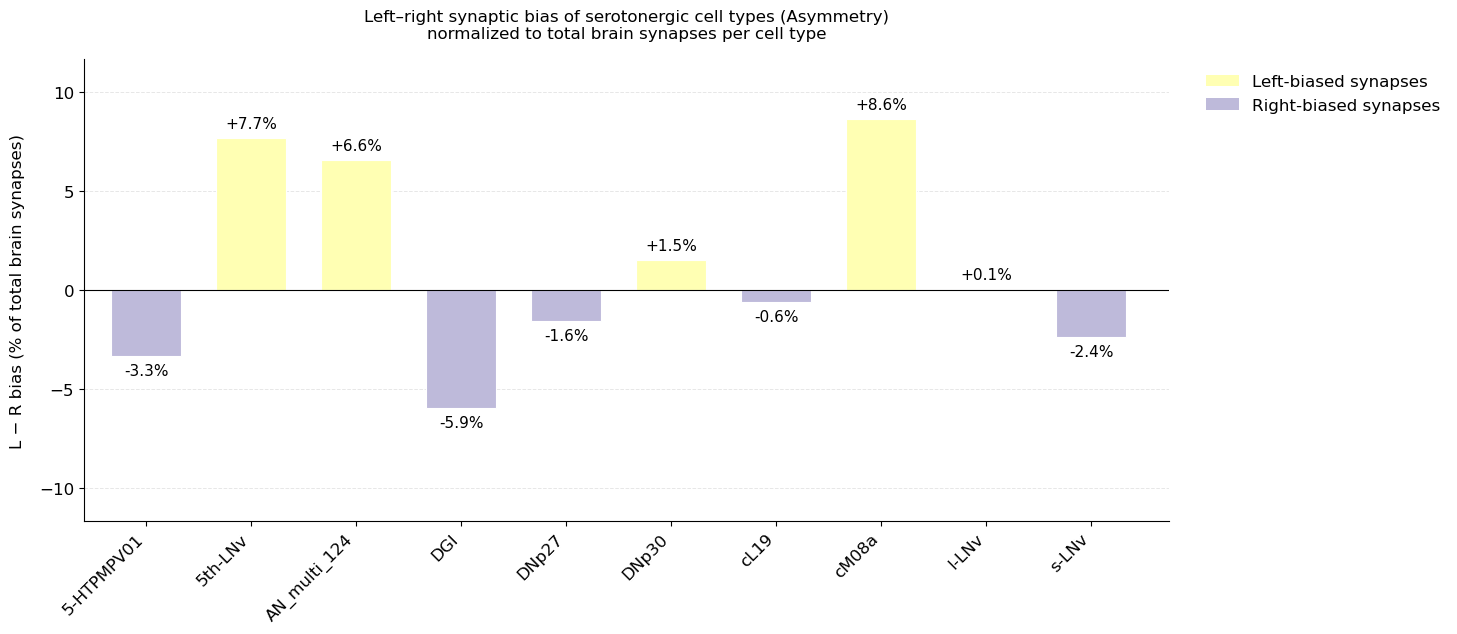


Done!
C:\Users\krist\OneDrive\Desktop\B' module\serotonergic_optic_lobe_heatmap\serotonergic_optic_lobe_LR_bias_brain_normalized.png
C:\Users\krist\OneDrive\Desktop\B' module\serotonergic_optic_lobe_heatmap\serotonergic_optic_lobe_LR_bias_brain_normalized.pdf


In [32]:
"""
GOAL: For selected serotonergic cell types, show where their synapses sit in the
optic lobe (AME, ME, LO, LOP; left vs right) relative to their TOTAL synapses in
the whole brain.

NORMALIZATION: Percentages are divided by each cell type's total synapse count
across ALL neuropils of the brain (not just the optic lobe).

PLOT: Bar chart of the left-right (L-R) synaptic bias (asymmetry) per cell type.
      Positive = more optic lobe synapses on the left, negative = on the right.
      LR_NORMALIZATION below switches the denominator of the bias between
      "brain" (whole-brain total) and "optic_lobe" (original behaviour).
"""

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch


# ============================================================
# Settings
# ============================================================

# "brain"      -> (L - R) / total brain synapses of the cell type * 100
# "optic_lobe" -> (L - R) / (L + R) * 100   (original formula)
LR_NORMALIZATION = "brain"

# Set True if the _L/_R labels of your data release are inverted
# (the FlyWire FAFB dataset was left/right inverted during acquisition).
# Only change this if your CSV has not been corrected already.
SWAP_LR = False


# ============================================================
# Paths
# ============================================================

folder = Path(r"C:\Users\krist\OneDrive\Desktop\B' module")

input_file = folder / "connections_princeton_SER_only_annotated_whole_brain.csv"

output_dir = folder / "serotonergic_optic_lobe_heatmap"
output_dir.mkdir(parents=True, exist_ok=True)


# ============================================================
# Columns
# ============================================================

cell_type_col = "annotation_primary_type"
neuropil_col = "neuropil"
syn_count_col = "syn_count"


# ============================================================
# Cell types
# ============================================================

selected_cell_types = [
    "5-HTPMPV01",
    "5th-LNv",
    "AN_multi_124",
    "DGI",
    "DNp27",
    "DNp30",
    "cL19",
    "cM08a",
    "l-LNv",
    "s-LNv"
]


# ============================================================
# Neuropils
# ============================================================

neuropils = [
    "AME_L", "AME_R",
    "ME_L", "ME_R",
    "LO_L", "LO_R",
    "LOP_L", "LOP_R"
]

left_neuropils = ["AME_L", "ME_L", "LO_L", "LOP_L"]
right_neuropils = ["AME_R", "ME_R", "LO_R", "LOP_R"]

if SWAP_LR:
    left_neuropils, right_neuropils = right_neuropils, left_neuropils


# ============================================================
# Appearance
# ============================================================

FONT_SIZE = 12
FONT_WEIGHT = "normal"

FIG_WIDTH = 14
FIG_HEIGHT = 6


# ============================================================
# Read and clean data
# ============================================================

df = pd.read_csv(input_file)

df = df[df[cell_type_col].isin(selected_cell_types)].copy()

df = df.dropna(subset=[cell_type_col, neuropil_col, syn_count_col])

df[neuropil_col] = df[neuropil_col].astype(str).str.strip()

df[syn_count_col] = pd.to_numeric(df[syn_count_col], errors="coerce")

df = df.dropna(subset=[syn_count_col])


# ============================================================
# NEW: Total synapses per cell type across ALL neuropils
#
#    Computed BEFORE restricting to the optic lobe, so this is
#    the whole-brain total used as the denominator.
# ============================================================

brain_totals = (
    df.groupby(cell_type_col)[syn_count_col]
    .sum()
    .reindex(selected_cell_types)
    .fillna(0)
)

# Restrict to the 8 optic lobe neuropils from here on
df = df[df[neuropil_col].isin(neuropils)].copy()


# ============================================================
# Aggregate: cell type x neuropil
# ============================================================

grouped = (
    df.groupby([cell_type_col, neuropil_col], as_index=False)[syn_count_col]
    .sum()
)


# ============================================================
# Complete matrix (every cell type has all 8 neuropils)
# ============================================================

full_index = pd.MultiIndex.from_product(
    [selected_cell_types, neuropils],
    names=[cell_type_col, neuropil_col]
)

grouped = (
    grouped
    .set_index([cell_type_col, neuropil_col])
    .reindex(full_index, fill_value=0)
    .reset_index()
)

count_data = (
    grouped
    .pivot(index=cell_type_col, columns=neuropil_col, values=syn_count_col)
    .reindex(index=selected_cell_types, columns=neuropils)
    .fillna(0)
)


# ============================================================
# Percentages of the TOTAL BRAIN synapses per cell type
#
#    Each value = synapses in that optic lobe neuropil
#                 / total synapses of the cell type in the brain * 100
#    Rows therefore sum to the cell type's optic lobe fraction
#    of the whole brain, not to 100%.
# ============================================================

brain_totals_safe = brain_totals.replace(0, np.nan)

percentage_data = (
    count_data.div(brain_totals_safe, axis=0) * 100
).fillna(0)

optic_lobe_totals = count_data.sum(axis=1)

optic_lobe_fraction_of_brain = (
    optic_lobe_totals / brain_totals_safe * 100
).fillna(0)


# ============================================================
# Left / right totals and L-R bias (asymmetry)
# ============================================================

left_totals = count_data[left_neuropils].sum(axis=1)
right_totals = count_data[right_neuropils].sum(axis=1)

combined_totals = left_totals + right_totals

if LR_NORMALIZATION == "brain":
    # (L - R) relative to the whole-brain total of the cell type
    asymmetry_percent = (
        (left_totals - right_totals) / brain_totals_safe * 100
    ).fillna(0)
    y_label = "L − R bias (% of total brain synapses)"
    plot_title = (
        "Left–right synaptic bias of serotonergic cell types (Asymmetry)\n"
        "normalized to total brain synapses per cell type"
    )
    min_y_limit = 5
elif LR_NORMALIZATION == "optic_lobe":
    asymmetry_percent = pd.Series(
        np.where(
            combined_totals != 0,
            (left_totals - right_totals) / combined_totals * 100,
            0
        ),
        index=count_data.index
    )
    y_label = "L − R bias (% of optic lobe synapses)"
    plot_title = "Left–right synaptic bias of serotonergic cell types (Asymmetry)"
    min_y_limit = 20
else:
    raise ValueError("LR_NORMALIZATION must be 'brain' or 'optic_lobe'")


# ============================================================
# Summary printout (quick sanity check)
# ============================================================

summary_table = pd.DataFrame({
    "brain_total": brain_totals,
    "optic_lobe_total": optic_lobe_totals,
    "optic_lobe_%_of_brain": optic_lobe_fraction_of_brain,
    "left": left_totals,
    "right": right_totals,
    "L_minus_R_percent": asymmetry_percent
})

print("\nSummary per cell type:")
print(summary_table.round(2))

missing_types = [ct for ct in selected_cell_types if brain_totals[ct] == 0]
if missing_types:
    print("\nWARNING: no synapses found in the data for:", missing_types)


# ============================================================
# Save data
# ============================================================

count_data.to_csv(output_dir / "serotonergic_optic_lobe_raw_counts.csv")

percentage_data.to_csv(
    output_dir / "serotonergic_optic_lobe_percent_of_brain.csv"
)

summary_table.to_csv(
    output_dir / "serotonergic_optic_lobe_summary_brain_normalized.csv"
)

asymmetry_percent.to_csv(
    output_dir / "serotonergic_left_right_asymmetry.csv",
    header=["L_minus_R_percent"]
)

percentage_with_asymmetry = percentage_data.copy()
percentage_with_asymmetry["L_minus_R_percent"] = asymmetry_percent

percentage_with_asymmetry.to_csv(
    output_dir / "serotonergic_percent_of_brain_with_asymmetry.csv"
)


# ============================================================
# L-R bias colors (palette unchanged)
#
#    Pulled from matplotlib's built-in "Set3" colormap.
#    Set3[1] = left-biased, Set3[2] = right-biased.
#    A simple two-color scheme: one color means "more synapses
#    on the Left", the other "more synapses on the Right".
# ============================================================

set3 = plt.get_cmap("Set3").colors

bias_left_color = set3[1]
bias_right_color = set3[2]


# ============================================================
# Figure: L-R bias panel
# ============================================================

fig, ax_bias = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT))

x_spacing = 1.35
x = np.arange(len(selected_cell_types)) * x_spacing
bar_width = 0.9

bar_colors = [
    bias_left_color if value >= 0 else bias_right_color
    for value in asymmetry_percent.values
]

ax_bias.bar(
    x,
    asymmetry_percent.values,
    width=bar_width,
    color=bar_colors,
    edgecolor="white",
    linewidth=0.8
)

ax_bias.axhline(0, color="black", linewidth=0.8)


# ============================================================
# Y-axis limits (scaled to the data, with headroom)
# ============================================================

y_limit = max(min_y_limit, np.abs(asymmetry_percent.values).max() * 1.35)

ax_bias.set_ylim(-y_limit, y_limit)


# ============================================================
# Bias value labels (offset scales with the axis range)
# ============================================================

label_offset = y_limit * 0.03

for i, value in enumerate(asymmetry_percent.values):

    offset = label_offset if value >= 0 else -label_offset

    ax_bias.text(
        x[i],
        value + offset,
        f"{value:+.1f}%",
        ha="center",
        va="bottom" if value >= 0 else "top",
        fontsize=FONT_SIZE - 1,
        fontweight=FONT_WEIGHT
    )


# ============================================================
# Axis labels and title
# ============================================================

ax_bias.set_ylabel(
    y_label,
    fontsize=FONT_SIZE,
    fontweight=FONT_WEIGHT,
    labelpad=10
)

ax_bias.set_title(
    plot_title,
    fontsize=FONT_SIZE,
    fontweight=FONT_WEIGHT,
    pad=15
)

ax_bias.tick_params(axis="y", labelsize=FONT_SIZE)

ax_bias.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.3)
ax_bias.set_axisbelow(True)

ax_bias.spines["top"].set_visible(False)
ax_bias.spines["right"].set_visible(False)


# ============================================================
# X-axis: cell type names
# ============================================================

ax_bias.set_xticks(x)

ax_bias.set_xticklabels(
    selected_cell_types,
    rotation=45,
    ha="right",
    fontsize=FONT_SIZE,
    fontweight=FONT_WEIGHT
)

ax_bias.set_xlim(x[0] - 0.8, x[-1] + 1.0)


# ============================================================
# Legend
# ============================================================

bias_legend_handles = [
    Patch(facecolor=bias_left_color, label="Left-biased synapses"),
    Patch(facecolor=bias_right_color, label="Right-biased synapses")
]

bias_legend = ax_bias.legend(
    handles=bias_legend_handles,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
    fontsize=FONT_SIZE
)

for text in bias_legend.get_texts():
    text.set_fontweight(FONT_WEIGHT)


# ============================================================
# Save
# ============================================================

output_png = output_dir / "serotonergic_optic_lobe_LR_bias_brain_normalized.png"
output_pdf = output_dir / "serotonergic_optic_lobe_LR_bias_brain_normalized.pdf"

fig.savefig(output_png, dpi=300, bbox_inches="tight")
fig.savefig(output_pdf, bbox_inches="tight")

plt.show()
plt.close(fig)

print("\nDone!")
print(output_png)
print(output_pdf)

Relative number of unique connections across optic lobe neuropils (normalization to the whole brain level)

Number of rows (before filtering): 211695

Columns in dataset:
['pre_root_id', 'post_root_id', 'neuropil', 'syn_count', 'nt_type', 'annotation_primary_type', 'annotation_additional_type(s)', 'pre_name', 'pre_group', 'post_name', 'post_group']

Cell types in dataset:
['l-LNv' 'R8' 'R1-6' 'L3' 'cM08a' 'DNp27' 'SLP444' 'cL19' 'AN_multi_124'
 'CSD' '5th-LNv' 'DNp30' 'NPFL1-I' 'CB2188' 'AVLP218b' 'DNg30' 'SMP001'
 'AVLP594' 'AVLP219a' 'AN_SLP_AVLP_1' 'DNp29' 'SLP304b' 'CRZ01' 'T1'
 'CB1101' 'AVLP441' 'CL107' 'SMPp&v1B_H01' 'DNp62' 'SLP403' 'R7' 'CL255'
 '5-HTPMPV01' 'lLN2X03' 'SMP582' 'lLN2T_c' 'ORN_DM2' 'FB1A' 'CB0262'
 'lLN2T_b' 'ORN_VA1v' 'vDeltaI_a' 'ORN_DA4l' 'FB4Y' 'AN_GNG_77' 'ORN_DC1'
 'AN_GNG_SAD_28' 'lLN1_a' 'ORN_DL4' 'BM_InOm' 'LAL082' 'CB0212' 'lLN2T_e'
 'SMPp&v1B_M02' 'ORN_VA2' 'AVLP461' 'lLN2X05' 'IB048' 'GNG800f' 'vDeltaC'
 'ORN_DM3' 'lLN2X11' 'ATL034' 'AN_GNG_SAD_22' 'ORN_VL1' 'CB0878' 'ORN_DL3'
 'CB0602' nan 'AN_FLA_SMP_2' 'SMP590' 'CB0722' 'CB4148' 'AN_GNG_69' 'FB4J'
 'CB1

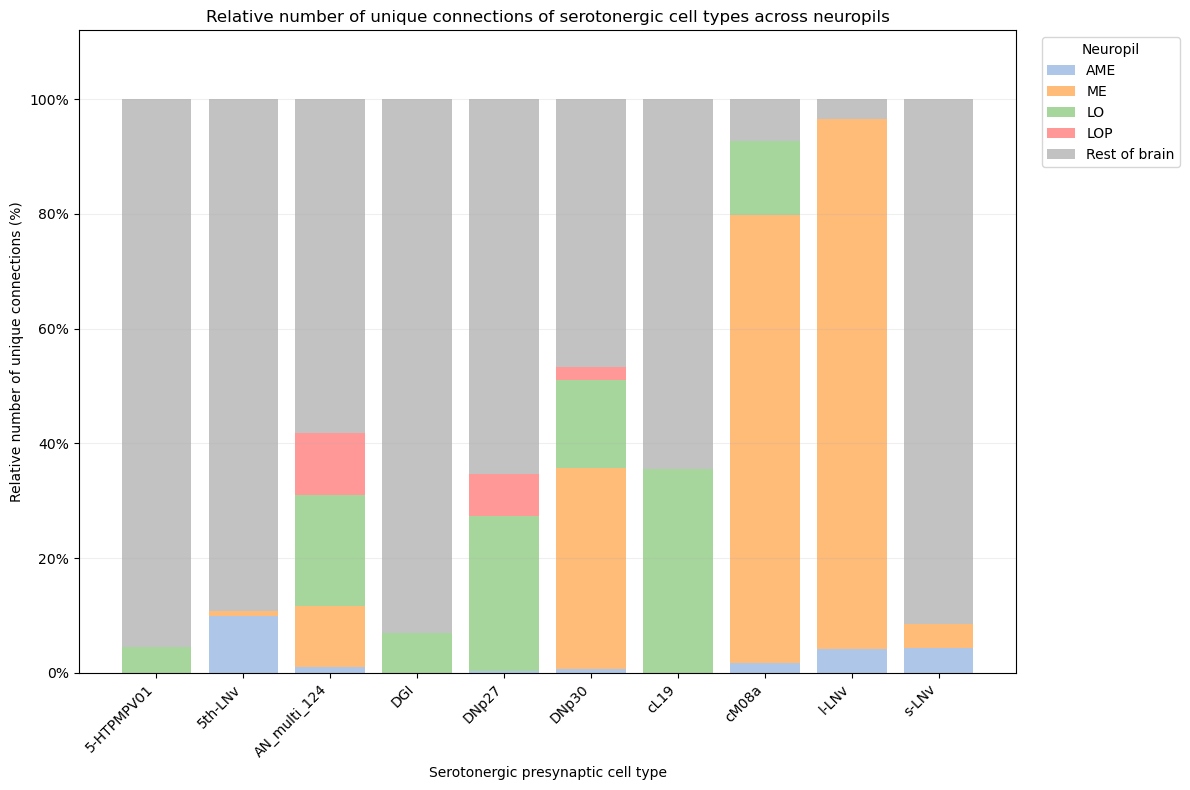


Done!

PNG:
C:\Users\krist\OneDrive\Desktop\B' module\serotonergic_unique_postsynaptic_partners_across_neuropils\serotonergic_unique_connection_distribution_filtered.png

SVG:
C:\Users\krist\OneDrive\Desktop\B' module\serotonergic_unique_postsynaptic_partners_across_neuropils\serotonergic_unique_connection_distribution_filtered.svg

Percentage table:
C:\Users\krist\OneDrive\Desktop\B' module\serotonergic_unique_postsynaptic_partners_across_neuropils\serotonergic_unique_connection_percentages_filtered.csv

Counts per region table:
C:\Users\krist\OneDrive\Desktop\B' module\serotonergic_unique_postsynaptic_partners_across_neuropils\serotonergic_unique_connection_counts_per_region.csv

Overall unique connections table:
C:\Users\krist\OneDrive\Desktop\B' module\serotonergic_unique_postsynaptic_partners_across_neuropils\serotonergic_unique_connections_overall.csv


In [43]:
# Main goal of the following code: For 10 selected serotonergic cell types (identified from Codex), we determine where in the brain
# their UNIQUE CONNECTIONS are located, specifically how many lie in the D. melanogaster optic lobe (OL) regions (AME, ME, LO, LOP),
# as compared to the rest of the brain.

# Definition: a unique connection is one unique pair of (serotonergic cell type, postsynaptic neuron). In other words, for every
# serotonergic cell type we count how many different postsynaptic neurons it connects to, no matter how many presynaptic neurons
# of that cell type contact the same partner or how many synapses they form. The same postsynaptic neuron can receive input from
# a cell type in several neuropils, so it is counted once in EACH region in which it occurs. Because of this, the percentages below
# are calculated relative to the sum of the regional counts of a cell type (so every bar adds up to 100%). The number printed above
# each bar (n) is the number of unique postsynaptic neurons of that cell type overall, where every neuron is counted only once.

# What does the plot show? A 100% stacked bar chart with one bar per serotonergic cell type. Each bar shows the percentage of that
# cell type's unique connections (postsynaptic partners) in AME, ME, LO, LOP and "Rest of brain" (Left-Right hemispheres are merged
# for each neuropil region). The y-axis is percentage of unique connections, and the x-axis is the serotonergic cell type.
# The plot shows the relative distribution of unique connections across the five regions for each cell type, rather than absolute counts.

#######################################################################################################################################

# We import the necessary libraries for file handling, data manipulation, and plotting.

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# We define the input and output paths. The input is a filtered CSV file containing synapse data for serotonergic cell types,
# and the output is a folder where we will save the resulting plots.

relative_synapse_count_folder = Path(r"C:\Users\krist\OneDrive\Desktop\B' module")

# The filtered CSV (input file)
input_file = relative_synapse_count_folder / "connections_princeton_SER_only_annotated_whole_brain.csv"

# The output folder for the plots
output_dir = relative_synapse_count_folder / "serotonergic_unique_postsynaptic_partners_across_neuropils"
output_dir.mkdir(parents=True, exist_ok=True)

# We define the column names in the input CSV that we will use for the analysis.
# post_id_col identifies the postsynaptic neuron. If it is left as None, the script tries to find it automatically
# (a column containing "post" and "id"). If that fails, it prints all column names so you can fill it in by hand,
# e.g. post_id_col = "post_root_id_720575940..."

cell_type_col = "annotation_primary_type"
neuropil_col = "neuropil"
syn_count_col = "syn_count"

post_id_col = None

# We read the input CSV file into a pandas DataFrame and print the number of rows before filtering, as well as the
# unique cell types present in the dataset and the column names.

data_frame_unique_connections = pd.read_csv(input_file)

print("Number of rows (before filtering):", len(data_frame_unique_connections))

print("\nColumns in dataset:")
print(list(data_frame_unique_connections.columns))

print("\nCell types in dataset:")
print(data_frame_unique_connections[cell_type_col].unique())

# We find the postsynaptic ID column automatically if it was not set above.


def find_id_column(columns, side):

    candidates = [
        c for c in columns
        if side in c.lower()
        and "id" in c.lower()
        and "annotation" not in c.lower()
        and "type" not in c.lower()
    ]

    # Prefer columns that look like root IDs
    root_candidates = [c for c in candidates if "root" in c.lower()]

    if root_candidates:
        return root_candidates[0]

    if candidates:
        return candidates[0]

    return None


if post_id_col is None:
    post_id_col = find_id_column(data_frame_unique_connections.columns, "post")

if post_id_col is None:
    raise ValueError(
        "Could not find the postsynaptic ID column automatically. "
        "Set post_id_col at the top of the script using the column names printed above."
    )

print("\nUsing postsynaptic ID column:", post_id_col)

# We filter the DataFrame to only include the 10 selected serotonergic cell types, and print the number of rows after filtering.

selected_serotonergic_cell_types = [
    "5-HTPMPV01",
    "5th-LNv",
    "AN_multi_124",
    "DGI",
    "DNp27",
    "DNp30",
    "cL19",
    "cM08a",
    "l-LNv",
    "s-LNv"
]

data_frame_unique_connections = data_frame_unique_connections[
    data_frame_unique_connections[cell_type_col].isin(selected_serotonergic_cell_types)
].copy()

# We check if any of the selected cell types are missing from the filtered DataFrame, and print a warning if so.

print("\nNumber of rows (after filtering):", len(data_frame_unique_connections))

found_types = set(data_frame_unique_connections[cell_type_col].unique())
missing_types = [ct for ct in selected_serotonergic_cell_types if ct not in found_types]

if missing_types:
    print("\nWARNING: these requested cell types had 0 matching rows:")
    print(missing_types)
    print("Double-check spelling/formatting against the actual unique values above.")

# We clean the DataFrame by dropping rows with missing values in the relevant columns, and converting the synapse count column to numeric
# because it may have been read as a string. We then drop any rows where the synapse count is still missing after conversion.
# (The synapse count is not used for the unique connection counts, but we keep the same cleaning as before.)

data_frame_unique_connections = data_frame_unique_connections.dropna(
    subset=[
        cell_type_col,
        neuropil_col,
        syn_count_col,
        post_id_col
    ]
).copy()

data_frame_unique_connections[syn_count_col] = pd.to_numeric(
    data_frame_unique_connections[syn_count_col],
    errors="coerce"
)

data_frame_unique_connections = data_frame_unique_connections.dropna(
    subset=[syn_count_col]
)

# We define the target neuropil regions of interest for the analysis, which are AME, ME, LO, and LOP.
# All other neuropil regions will be classified as "Rest of brain" in the analysis.

#    AME for the Accessory Medulla
#    ME for the Medulla
#    LO for the Lobula
#    LOP for the Lobula Plate
#
#    Everything else = Rest of brain
# ============================================================

target_neuropil_regions = {
    "AME",  # accessory medulla
    "ME",   # medulla
    "LO",   # lobula
    "LOP"   # lobula plate
}

# We define a function to classify each neuropil region in the DataFrame.
# If the neuropil region ends with "L" or "R", we remove that suffix to merge left and right hemispheres.


def classify_neuropil(neuropil):

    neuropil = str(neuropil).strip()

    if neuropil.endswith("_L") or neuropil.endswith("_R"):
        neuropil = neuropil[:-2]

    if neuropil in target_neuropil_regions:
        return neuropil

    return "Rest of brain"


data_frame_unique_connections["region"] = data_frame_unique_connections[neuropil_col].apply(
    classify_neuropil
)

# We count the unique connections for each combination of cell type and region.
# Difference from the synapse count version: instead of summing synapse counts, we first remove duplicate
# (cell type, region, postsynaptic neuron) rows, so that every postsynaptic neuron counts only once per cell type and region
# (e.g. a partner contacted in ME_L and ME_R counts once in ME), and then count the remaining rows.

unique_partners_per_region = data_frame_unique_connections.drop_duplicates(
    subset=[
        cell_type_col,
        "region",
        post_id_col
    ]
)

summary_connection_counts = (
    unique_partners_per_region
    .groupby(
        [
            cell_type_col,
            "region"
        ]
    )
    .size()
    .reset_index(name="unique_connections")
)

# We calculate the total number of unique connections (postsynaptic neurons) for each cell type overall, where every neuron is
# counted only ONCE, regardless of how many regions it occurs in. This is the number (n) shown above each bar and saved in
# the overall table.

unique_partners_overall = data_frame_unique_connections.drop_duplicates(
    subset=[
        cell_type_col,
        post_id_col
    ]
)

overall_unique_connections = (
    unique_partners_overall
    .groupby(cell_type_col)
    .size()
    .reindex(selected_serotonergic_cell_types)
    .fillna(0)
    .astype(int)
)

# We calculate the total of the regional counts for each cell type by summing the counts across all regions for that cell type.
# Difference from above: because a partner can be counted in several regions, this sum can be larger than the overall total, and it is
# the denominator that makes every bar add up to 100%. We use transform ("sum") to create a Series that aligns with the DataFrame,
# so we can calculate percentages in the next step.

total_per_cell_type = (
    summary_connection_counts
    .groupby(cell_type_col)["unique_connections"]
    .transform("sum")
)

# We calculate the percentage of unique connections in each region for each cell type by dividing the count for that region by the
# total of the regional counts for that cell type, and multiplying by 100 to get a percentage.

summary_connection_counts["percentage"] = (
    summary_connection_counts["unique_connections"]
    / total_per_cell_type
    * 100
)

# We define the list of neuropil regions in the order we want them to appear in the plot, which is AME, ME, LO, LOP, and "Rest of brain".

neuropil_regions = [
    "AME",
    "ME",
    "LO",
    "LOP",
    "Rest of brain"
]

# We create a full index of all combinations of cell types and neuropil regions, so that we can ensure that every cell type has an entry
# for every neuropil region, even if the count is zero. This is important for plotting, so that all bars have the same number of
# segments.

cell_types = sorted(
    summary_connection_counts[cell_type_col].unique()
)

full_index = pd.MultiIndex.from_product(
    [
        cell_types,
        neuropil_regions
    ],
    names=[
        cell_type_col,
        "region"
    ]
)

# We reindex the summary DataFrame to include all combinations of cell types and neuropil regions, filling in any missing
# combinations with zero. We reset the index to turn the MultiIndex back into columns.

summary_connection_counts = (
    summary_connection_counts
    .set_index(
        [
            cell_type_col,
            "region"
        ]
    )
    .reindex(
        full_index,
        fill_value=0
    )
    .reset_index()
)

# We pivot the summary DataFrame to create a new DataFrame where the index is the cell type, the columns are the neuropil regions,
# and the values are the percentages of unique connections in each region. We fill any missing values with zero, so that every cell
# type has an entry for every neuropil region. We also ensure that the columns are in the order we want for plotting.

plot_data = (
    summary_connection_counts
    .pivot(
        index=cell_type_col,
        columns="region",
        values="percentage"
    )
    .fillna(0)
)

plot_data = plot_data[
    neuropil_regions
]

# We also create the same table with the raw numbers of unique connections per region (not percentages), for reference.

count_data = (
    summary_connection_counts
    .pivot(
        index=cell_type_col,
        columns="region",
        values="unique_connections"
    )
    .fillna(0)
    .astype(int)
)

count_data = count_data[
    neuropil_regions
]

# We print the percentage totals for each cell type, which should sum to 100% across all neuropil regions.
# This is a sanity check to ensure that the percentages were calculated correctly.

print("\nPercentage totals:")

for cell_type, total in plot_data.sum(axis=1).items():

    print(
        f"{cell_type}: {total:.2f}%"
    )

# We print the number of unique connections per cell type (every postsynaptic neuron counted once) and per region.

print("\nUnique connections (postsynaptic neurons) per cell type (overall, every neuron counted once):")
print(overall_unique_connections)

print("\nUnique connections per cell type and region (a neuron counts once in each region it occurs in):")
print(count_data)

# We save the percentage data, the raw counts per region, and the overall counts to CSV files in the output directory, so that we
# have a record of the calculated values for further analysis or verification of the results.

values_file = (
    output_dir /
    "serotonergic_unique_connection_percentages_filtered.csv"
)

counts_file = (
    output_dir /
    "serotonergic_unique_connection_counts_per_region.csv"
)

overall_file = (
    output_dir /
    "serotonergic_unique_connections_overall.csv"
)

plot_data.to_csv(
    values_file
)

count_data.to_csv(
    counts_file
)

overall_unique_connections.to_csv(
    overall_file,
    header=["unique_postsynaptic_partners_overall"]
)

# We create a stacked bar chart to visualize the relative distribution of unique connections of serotonergic cell types across
# neuropil regions.

fig, ax = plt.subplots(
    figsize=(
        max(12, len(plot_data) * 1.0),
        8
    )
)

# We define a color palette for the neuropil regions. Each region is assigned a specific
# color for visual distinction in the stacked bar chart. The colors are chosen to be visually distinct and easily identifiable.
set3 = plt.get_cmap("Set3").colors

region_colors = {
    "AME": "#AEC7E8",
    "ME": "#FFBB78",
    "LO": "#A6D69C",
    "LOP": "#FF9896",
    "Rest of brain": "#C2C2C2"
}

bottom = None

# We iterate over the neuropil regions and plot the percentage of unique connections for each region as a stacked bar for each
# serotonergic cell type. The 'bottom' parameter is used to stack the bars on top of each other, creating a cumulative effect.

for region in neuropil_regions:

    values = plot_data[region].values

    ax.bar(
        plot_data.index,
        values,
        bottom=bottom,
        label=region,
        color=region_colors[region]
    )

    if bottom is None:
        bottom = values.copy()

    else:
        bottom += values

# We write the overall number of unique connections (n) above each bar, so that the absolute numbers are visible next to
# the relative distribution. Bars from cell types with very few connections should be interpreted with caution.


# We set the x-axis label, y-axis label, and title for the plot to provide context and information about what the plot represents.

ax.set_xlabel(
    "Serotonergic presynaptic cell type"
)

ax.set_ylabel(
    "Relative number of unique connections (%)"
)

ax.set_title(
    "Relative number of unique connections of serotonergic cell types across neuropils"
)

# We add extra headroom above 100% on the y-axis to ensure that the top of the bars does not touch the top of the plot area
# and to leave space for the n labels. The y-axis is formatted to show percentages, and tick marks are set to only go up to 100% to
# emphasize that the headroom is empty space rather than a labeled range.

y_headroom = 12  # extra space above 100% for visual clarity

ax.set_ylim(
    0,
    100 + y_headroom
)

ax.yaxis.set_major_formatter(
    PercentFormatter(100)
)

# We set the y-axis ticks to be at intervals of 20%, which provides a clear and easy-to-read scale.

ax.set_yticks(range(0, 101, 20))

# We set the x-axis ticks to correspond to the number of serotonergic cell types, ensuring that each bar is labeled correctly.

ax.set_xticks(
    range(len(plot_data.index))
)

ax.set_xticklabels(
    plot_data.index,
    rotation=45,
    ha="right"
)

# We add a legend to the plot to indicate which colors correspond to which neuropil regions. The legend is placed outside the main plot area.

ax.legend(
    title="Neuropil",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)


ax.grid(
    axis="y",
    alpha=0.2
)

# We adjust the layout of the plot to ensure that all elements are displayed properly and that there is no overlap between labels, titles, and
# the plot area. This is especially important when saving the plot to a file to ensure that all elements are visible.

fig.tight_layout()


png_file = (
    output_dir /
    "serotonergic_unique_connection_distribution_filtered.png"
)

svg_file = (
    output_dir /
    "serotonergic_unique_connection_distribution_filtered.svg"
)

fig.savefig(
    png_file,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    svg_file,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)

# We print the paths to the saved plot files and the CSV files, so that the user knows where to find the output files.

print("\nDone!")

print("\nPNG:")
print(png_file)

print("\nSVG:")
print(svg_file)

print("\nPercentage table:")
print(values_file)

print("\nCounts per region table:")
print(counts_file)

print("\nOverall unique connections table:")
print(overall_file)

Absolute number of unique connections across optic lobe neuropils

Number of rows (before filtering): 211695

Columns in dataset:
['pre_root_id', 'post_root_id', 'neuropil', 'syn_count', 'nt_type', 'annotation_primary_type', 'annotation_additional_type(s)', 'pre_name', 'pre_group', 'post_name', 'post_group']

Cell types in dataset:
['l-LNv' 'R8' 'R1-6' 'L3' 'cM08a' 'DNp27' 'SLP444' 'cL19' 'AN_multi_124'
 'CSD' '5th-LNv' 'DNp30' 'NPFL1-I' 'CB2188' 'AVLP218b' 'DNg30' 'SMP001'
 'AVLP594' 'AVLP219a' 'AN_SLP_AVLP_1' 'DNp29' 'SLP304b' 'CRZ01' 'T1'
 'CB1101' 'AVLP441' 'CL107' 'SMPp&v1B_H01' 'DNp62' 'SLP403' 'R7' 'CL255'
 '5-HTPMPV01' 'lLN2X03' 'SMP582' 'lLN2T_c' 'ORN_DM2' 'FB1A' 'CB0262'
 'lLN2T_b' 'ORN_VA1v' 'vDeltaI_a' 'ORN_DA4l' 'FB4Y' 'AN_GNG_77' 'ORN_DC1'
 'AN_GNG_SAD_28' 'lLN1_a' 'ORN_DL4' 'BM_InOm' 'LAL082' 'CB0212' 'lLN2T_e'
 'SMPp&v1B_M02' 'ORN_VA2' 'AVLP461' 'lLN2X05' 'IB048' 'GNG800f' 'vDeltaC'
 'ORN_DM3' 'lLN2X11' 'ATL034' 'AN_GNG_SAD_22' 'ORN_VL1' 'CB0878' 'ORN_DL3'
 'CB0602' nan 'AN_FLA_SMP_2' 'SMP590' 'CB0722' 'CB4148' 'AN_GNG_69' 'FB4J'
 'CB1

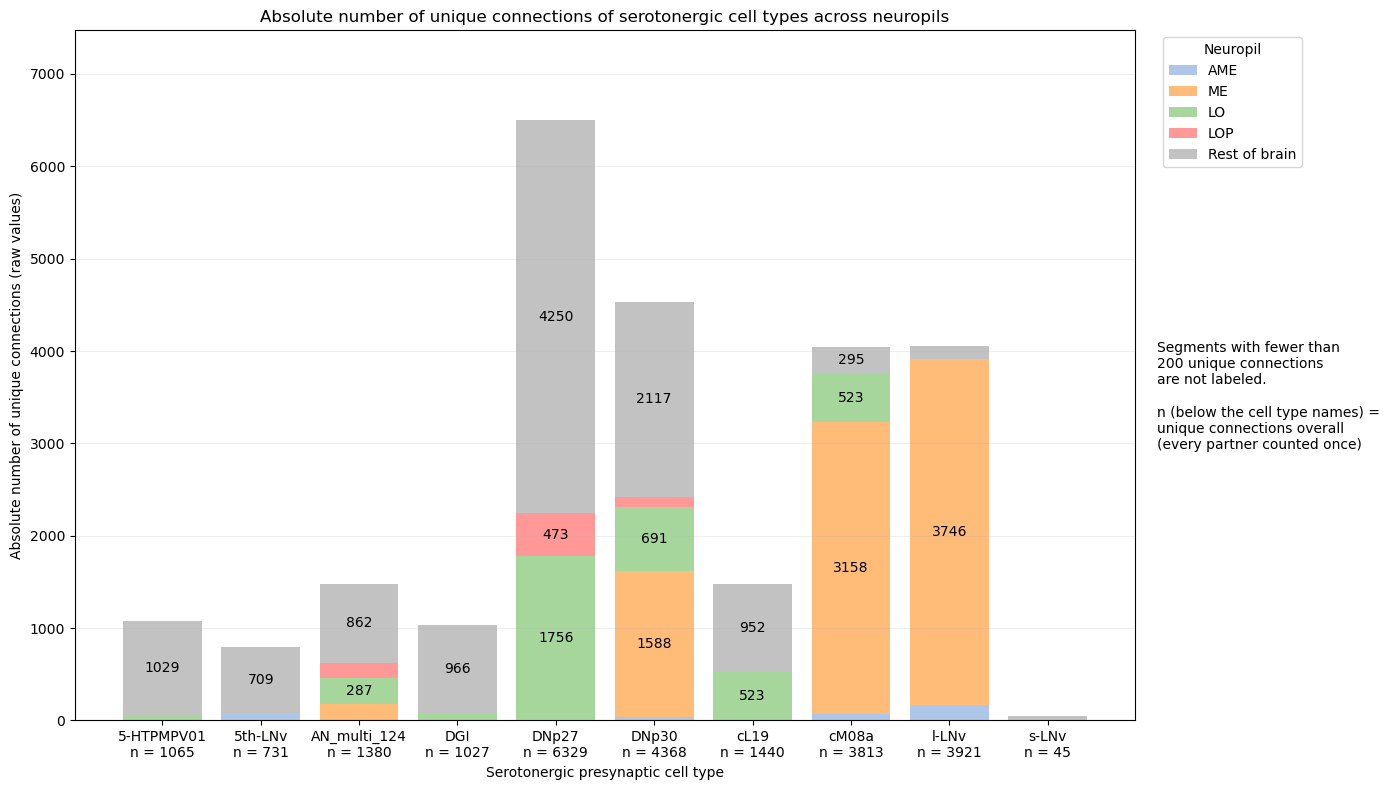


Done!

PNG:
C:\Users\krist\OneDrive\Desktop\B' module\serotonergic_unique_postsynaptic_partners_across_neuropils_raw\serotonergic_unique_connection_distribution_raw.png

SVG:
C:\Users\krist\OneDrive\Desktop\B' module\serotonergic_unique_postsynaptic_partners_across_neuropils_raw\serotonergic_unique_connection_distribution_raw.svg

Counts per region table:
C:\Users\krist\OneDrive\Desktop\B' module\serotonergic_unique_postsynaptic_partners_across_neuropils_raw\serotonergic_unique_connection_counts_per_region.csv

Overall unique connections table:
C:\Users\krist\OneDrive\Desktop\B' module\serotonergic_unique_postsynaptic_partners_across_neuropils_raw\serotonergic_unique_connections_overall.csv


In [41]:
# Main goal of the following code: For 10 selected serotonergic cell types (identified from Codex), we determine where in the brain
# their UNIQUE CONNECTIONS are located, specifically how many lie in the D. melanogaster optic lobe (OL) regions (AME, ME, LO, LOP),
# as compared to the rest of the brain, using the ABSOLUTE (raw) number of unique connections.

# Definition: a unique connection is one unique pair of (serotonergic cell type, postsynaptic neuron). In other words, for every
# serotonergic cell type we count how many different postsynaptic neurons it connects to, no matter how many presynaptic neurons
# of that cell type contact the same partner or how many synapses they form. The same postsynaptic neuron can receive input from
# a cell type in several neuropils, so it is counted once in EACH region in which it occurs. Because of this, the height of a stacked
# bar (the sum of the regional counts) can be larger than the number of unique postsynaptic neurons of that cell type overall.
# The number printed below the name of each cell type (n) is the number of unique postsynaptic neurons of that cell type
# overall, where every neuron is counted only once.

# What does the plot show? A stacked bar chart with one bar per serotonergic cell type. Each segment shows the absolute number of
# unique connections (postsynaptic partners) of that cell type in AME, ME, LO, LOP and "Rest of brain" (Left-Right hemispheres are
# merged for each neuropil region). The y-axis is the absolute (raw) number of unique connections, and the x-axis is the
# serotonergic cell type. Unlike the 100% stacked version, bar heights can be compared between cell types.

#######################################################################################################################################

# We import the necessary libraries for file handling, data manipulation, and plotting.

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# A segment is only labeled with its raw count if it has at least this many unique connections. Segments with fewer
# unique connections are left without a number, which keeps small segments from being cluttered with unreadable numbers.
# Set to 1 to label every non-zero segment.

MIN_LABEL_COUNT = 200

# We define the input and output paths. The input is a filtered CSV file containing synapse data for serotonergic cell types,
# and the output is a folder where we will save the resulting plots.

relative_synapse_count_folder = Path(r"C:\Users\krist\OneDrive\Desktop\B' module")

# The filtered CSV (input file)
input_file = relative_synapse_count_folder / "connections_princeton_SER_only_annotated_whole_brain.csv"

# The output folder for the plots
output_dir = relative_synapse_count_folder / "serotonergic_unique_postsynaptic_partners_across_neuropils_raw"
output_dir.mkdir(parents=True, exist_ok=True)

# We define the column names in the input CSV that we will use for the analysis.
# post_id_col identifies the postsynaptic neuron. If it is left as None, the script tries to find it automatically
# (a column containing "post" and "id"). If that fails, it prints all column names so you can fill it in by hand,
# e.g. post_id_col = "post_root_id_720575940..."

cell_type_col = "annotation_primary_type"
neuropil_col = "neuropil"
syn_count_col = "syn_count"

post_id_col = None

# We read the input CSV file into a pandas DataFrame and print the number of rows before filtering, as well as the
# unique cell types present in the dataset and the column names.

data_frame_unique_connections = pd.read_csv(input_file)

print("Number of rows (before filtering):", len(data_frame_unique_connections))

print("\nColumns in dataset:")
print(list(data_frame_unique_connections.columns))

print("\nCell types in dataset:")
print(data_frame_unique_connections[cell_type_col].unique())

# We find the postsynaptic ID column automatically if it was not set above.


def find_id_column(columns, side):

    candidates = [
        c for c in columns
        if side in c.lower()
        and "id" in c.lower()
        and "annotation" not in c.lower()
        and "type" not in c.lower()
    ]

    # Prefer columns that look like root IDs
    root_candidates = [c for c in candidates if "root" in c.lower()]

    if root_candidates:
        return root_candidates[0]

    if candidates:
        return candidates[0]

    return None


if post_id_col is None:
    post_id_col = find_id_column(data_frame_unique_connections.columns, "post")

if post_id_col is None:
    raise ValueError(
        "Could not find the postsynaptic ID column automatically. "
        "Set post_id_col at the top of the script using the column names printed above."
    )

print("\nUsing postsynaptic ID column:", post_id_col)

# We filter the DataFrame to only include the 10 selected serotonergic cell types, and print the number of rows after filtering.

selected_serotonergic_cell_types = [
    "5-HTPMPV01",
    "5th-LNv",
    "AN_multi_124",
    "DGI",
    "DNp27",
    "DNp30",
    "cL19",
    "cM08a",
    "l-LNv",
    "s-LNv"
]

data_frame_unique_connections = data_frame_unique_connections[
    data_frame_unique_connections[cell_type_col].isin(selected_serotonergic_cell_types)
].copy()

# We check if any of the selected cell types are missing from the filtered DataFrame, and print a warning if so.

print("\nNumber of rows (after filtering):", len(data_frame_unique_connections))

found_types = set(data_frame_unique_connections[cell_type_col].unique())
missing_types = [ct for ct in selected_serotonergic_cell_types if ct not in found_types]

if missing_types:
    print("\nWARNING: these requested cell types had 0 matching rows:")
    print(missing_types)
    print("Double-check spelling/formatting against the actual unique values above.")

# We clean the DataFrame by dropping rows with missing values in the relevant columns, and converting the synapse count column to numeric
# because it may have been read as a string. We then drop any rows where the synapse count is still missing after conversion.
# (The synapse count is not used for the unique connection counts, but we keep the same cleaning as before.)

data_frame_unique_connections = data_frame_unique_connections.dropna(
    subset=[
        cell_type_col,
        neuropil_col,
        syn_count_col,
        post_id_col
    ]
).copy()

data_frame_unique_connections[syn_count_col] = pd.to_numeric(
    data_frame_unique_connections[syn_count_col],
    errors="coerce"
)

data_frame_unique_connections = data_frame_unique_connections.dropna(
    subset=[syn_count_col]
)

# We define the target neuropil regions of interest for the analysis, which are AME, ME, LO, and LOP.
# All other neuropil regions will be classified as "Rest of brain" in the analysis.

#    AME for the Accessory Medulla
#    ME for the Medulla
#    LO for the Lobula
#    LOP for the Lobula Plate
#
#    Everything else = Rest of brain
# ============================================================

target_neuropil_regions = {
    "AME",  # accessory medulla
    "ME",   # medulla
    "LO",   # lobula
    "LOP"   # lobula plate
}

# We define a function to classify each neuropil region in the DataFrame.
# If the neuropil region ends with "L" or "R", we remove that suffix to merge left and right hemispheres.


def classify_neuropil(neuropil):

    neuropil = str(neuropil).strip()

    if neuropil.endswith("_L") or neuropil.endswith("_R"):
        neuropil = neuropil[:-2]

    if neuropil in target_neuropil_regions:
        return neuropil

    return "Rest of brain"


data_frame_unique_connections["region"] = data_frame_unique_connections[neuropil_col].apply(
    classify_neuropil
)

# We define the list of neuropil regions in the order we want them to appear in the plot, which is AME, ME, LO, LOP, and "Rest of brain".

neuropil_regions = [
    "AME",
    "ME",
    "LO",
    "LOP",
    "Rest of brain"
]

# We count the unique connections for each combination of cell type and region.
# Difference from the synapse count version: instead of summing synapse counts, we first remove duplicate
# (cell type, region, postsynaptic neuron) rows, so that every postsynaptic neuron counts only once per cell type and region
# (e.g. a partner contacted in ME_L and ME_R counts once in ME), and then count the remaining rows.

unique_partners_per_region = data_frame_unique_connections.drop_duplicates(
    subset=[
        cell_type_col,
        "region",
        post_id_col
    ]
)

# We create the table for plotting: the index is the cell type, the columns are the neuropil regions, and the values are the
# absolute numbers of unique connections. Missing combinations are filled with zero, so that every cell type has an entry for every
# neuropil region, even if the count is zero. This is important for plotting, so that all bars have the same number of segments.
# We also ensure that the columns are in the order we want for plotting.

cell_types = sorted(selected_serotonergic_cell_types)

plot_data = (
    unique_partners_per_region
    .groupby(
        [
            cell_type_col,
            "region"
        ]
    )
    .size()
    .unstack(fill_value=0)
    .reindex(
        index=cell_types,
        columns=neuropil_regions,
        fill_value=0
    )
    .astype(int)
)

# We calculate the total number of unique connections (postsynaptic neurons) for each cell type overall, where every neuron is
# counted only ONCE, regardless of how many regions it occurs in. This is the number (n) shown above each bar and saved in
# the overall table.

unique_partners_overall = data_frame_unique_connections.drop_duplicates(
    subset=[
        cell_type_col,
        post_id_col
    ]
)

overall_unique_connections = (
    unique_partners_overall
    .groupby(cell_type_col)
    .size()
    .reindex(cell_types)
    .fillna(0)
    .astype(int)
)

# We calculate the sum of the regional counts for each cell type, which is the height of the stacked bars. Because a partner can be
# counted in several regions, this sum can be larger than the overall number of unique connections (n).

regional_sum_per_cell_type = plot_data.sum(axis=1)

# We print the overall number of unique connections per cell type (every postsynaptic neuron counted once), the sum of the regional
# counts (bar height), and the counts per region.

print("\nUnique connections (postsynaptic neurons) per cell type:")

print(
    pd.DataFrame({
        "overall_unique_connections (n)": overall_unique_connections,
        "sum_of_regional_counts (bar height)": regional_sum_per_cell_type
    })
)

print("\nUnique connections per cell type and region (a neuron counts once in each region it occurs in):")
print(plot_data)

# We save the raw counts per region and the overall counts to CSV files in the output directory, so that we have a record of the
# calculated values for further analysis or verification of the results.

counts_file = (
    output_dir /
    "serotonergic_unique_connection_counts_per_region.csv"
)

overall_file = (
    output_dir /
    "serotonergic_unique_connections_overall.csv"
)

plot_data.to_csv(
    counts_file
)

overall_unique_connections.to_csv(
    overall_file,
    header=["unique_postsynaptic_partners_overall"]
)

# We create a stacked bar chart to visualize the absolute number of unique connections of serotonergic cell types across
# neuropil regions.

fig, ax = plt.subplots(
    figsize=(
        max(14, len(plot_data) * 1.3),
        8
    )
)

# We define a color palette for the neuropil regions. Each region is assigned a specific
# color for visual distinction in the stacked bar chart. The colors are chosen to be visually distinct and easily identifiable.

region_colors = {
    "AME": "#AEC7E8",
    "ME": "#FFBB78",
    "LO": "#A6D69C",
    "LOP": "#FF9896",
    "Rest of brain": "#C2C2C2"
}

# We calculate the highest bar, which is used for the y-axis limit and for the offset of the n labels.

max_total = max(regional_sum_per_cell_type.max(), 1)

bottom = np.zeros(len(plot_data))

# We iterate over the neuropil regions and plot the absolute number of unique connections for each region as a stacked bar for each
# serotonergic cell type. The 'bottom' parameter is used to stack the bars on top of each other, creating a cumulative effect.
# A raw count label is added in the center of each segment, skipping segments with fewer than MIN_LABEL_COUNT connections.

for region in neuropil_regions:

    values = plot_data[region].values

    ax.bar(
        plot_data.index,
        values,
        bottom=bottom,
        label=region,
        color=region_colors[region]
    )

    for i, value in enumerate(values):

        if value >= MIN_LABEL_COUNT:

            ax.text(
                i,
                bottom[i] + value / 2,
                f"{value}",
                ha="center",
                va="center"
            )

    bottom = bottom + values

# We set the x-axis label, y-axis label, and title for the plot to provide context and information about what the plot represents.

ax.set_xlabel(
    "Serotonergic presynaptic cell type"
)

ax.set_ylabel(
    "Absolute number of unique connections (raw values)"
)

ax.set_title(
    "Absolute number of unique connections of serotonergic cell types across neuropils"
)

# We add extra headroom above the tallest bar on the y-axis to ensure that the top of the bars and the n labels do not touch the
# top of the plot area. The y-axis is scaled automatically to the data.

ax.set_ylim(
    0,
    max_total * 1.15
)

# We set the x-axis ticks to correspond to the number of serotonergic cell types, ensuring that each bar is labeled correctly.

ax.set_xticks(
    range(len(plot_data.index))
)

# The name of each cell type is followed by its overall number of unique connections (n, every partner counted once) on a second
# line, so that n is shown below the name. n can be smaller than the bar height, because a partner that occurs in several regions
# is counted in each of them in the segments.

ax.set_xticklabels(
    [
        f"{cell_type}\nn = {overall_unique_connections[cell_type]}"
        for cell_type in plot_data.index
    ],
    rotation=0,
    ha="center"
)

# We add a legend to the plot to indicate which colors correspond to which neuropil regions. The legend is placed outside the main plot area.

ax.legend(
    title="Neuropil",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

# We add a small note next to the legend explaining why some segments have no count label and what n means.

ax.text(
    1.02,
    0.55,
    f"Segments with fewer than\n{MIN_LABEL_COUNT} unique connections\nare not labeled.\n\n"
    "n (below the cell type names) =\nunique connections overall\n(every partner counted once)",
    transform=ax.transAxes,
    va="top",
    ha="left"
)

ax.grid(
    axis="y",
    alpha=0.2
)

# We adjust the layout of the plot to ensure that all elements are displayed properly and that there is no overlap between labels, titles, and
# the plot area. This is especially important when saving the plot to a file to ensure that all elements are visible.

fig.tight_layout()


png_file = (
    output_dir /
    "serotonergic_unique_connection_distribution_raw.png"
)

svg_file = (
    output_dir /
    "serotonergic_unique_connection_distribution_raw.svg"
)

fig.savefig(
    png_file,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    svg_file,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)

# We print the paths to the saved plot files and the CSV files, so that the user knows where to find the output files.

print("\nDone!")

print("\nPNG:")
print(png_file)

print("\nSVG:")
print(svg_file)

print("\nCounts per region table:")
print(counts_file)

print("\nOverall unique connections table:")
print(overall_file)